<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/Deep_Galarkin_Method.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solving ODEs with the Deep Gakerkin Method

## Basic Version

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Define the Neural Network model
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()
        self.fc1=nn.Linear(1,200)
        self.fc2=nn.Linear(200,200)
        self.fc3=nn.Linear(200,1)


    def forward(self, t):
        x=self.fc1(t)
        x=torch.sigmoid(x)
        x=self.fc2(x)
        x=torch.sigmoid(x)
        x=self.fc3(x)


        return x

In [6]:
def set_seed(seed=42): # for reproducibility
    # NumPy
    np.random.seed(seed)

    # PyTorch CPU & GPU
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) # for multi-GPU setups

    # Configure PyTorch to be deterministic
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

We study the first-order linear Ordinary Differential Equation (ODE):

$$\frac{dy}{dt} = t - y(t)$$

subject to the initial condition:

$$y(0) = 1$$

Analytical Solution

The exact analytical solution to this initial value problem is:

$$y(t) = t - 1 + 2e^{-t}$$

We can verify this solution satisfies both the ODE and the initial condition:

- Initial Condition: $$y(0) = 0 - 1 + 2e^{0} = -1 + 2 = 1$$
- ODE Check: $$\frac{dy}{dt} = 1 - 2e^{-t}$$ $$t - y(t) = t - (t - 1 + 2e^{-t}) = 1 - 2e^{-t}$$Since both sides are equal, the solution is verified.


In [ ]:
# Define the true solution of the ODE
y0 = 1.0
def true_solution(t):
    return t - 1 + 2 * torch.exp(-t)

# Define the loss function for the ODE residual
def ode_loss(model, t_batch):
    t_batch.requires_grad_(True)
    y_pred = model(t_batch)

    # Compute dy/dt using autograd
    # TODO: Compute dy_dt

    # Residual of the ODE: dy/dt = t - y; dy(t)/dt = f(t, y(t)) where f(t,y) = t - y
    # TODO: Define residual

    return loss_ode

# Define the loss for the initial condition y(0) = 1
def initial_condition_loss(model):
    y0_pred = model(torch.tensor([[0.0]]))  # y(0)
    # TODO: initial condition loss
    return loss_ic

### Equal weights for losses

In [ ]:
# Main function to train the model
def train_ode_solver(model,
                     optimizer,
                     T = 5.0,
                     num_epochs = 500,
                     batch_size = 10,
                     with_plots = True):
    # Create a testing set of 100 points sampled uniformly from [0, T]
    t_test = torch.linspace(0, T, 100).unsqueeze(1)
    y_test_true = true_solution(t_test).detach()

    # Lists to store losses
    train_losses = []
    test_losses = []

    # Training loop
    for epoch in range(num_epochs):
        model.train()

        # Sample minibatch of time points uniformly in [0, T]
        t_batch = T * torch.rand(batch_size, 1)

        # Compute the total loss: ODE residual loss + initial condition loss
        # TODO: Total loss

        # Backpropagation and optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record train loss
        train_losses.append(loss.item())

        # Evaluate the model on the testing set every 10 epochs
        if epoch % 10 == 0:
            model.eval()
            with torch.no_grad():
                y_test_pred = model(t_test)
                test_loss = torch.mean((y_test_pred - y_test_true) ** 2)
                test_losses.append(test_loss.item())
                print(f'Epoch {epoch}, Test Loss: {test_loss.item()}')

                if with_plots:
                  # Plot the true solution and the learned solution by the NN
                  plt.figure(figsize=(8, 6))
                  plt.plot(t_test.numpy(), y_test_true.numpy(), 'r--', label="True Solution")
                  plt.plot(t_test.numpy(), y_test_pred.numpy(), 'b-', label="Learned Solution (NN)")
                  plt.legend()
                  plt.xlabel("t")
                  plt.ylabel("y(t)")
                  plt.title(f"Epoch {epoch}")
                  plt.show()

    return num_epochs, train_losses, test_losses

def plot_losses(num_epochs, train_losses, test_losses):
    # Plot train and test losses
    plt.figure(figsize=(8, 6))
    plt.semilogy(np.arange(num_epochs), train_losses, label='Train Loss')
    plt.semilogy(np.arange(0, num_epochs, 10), test_losses, label='Test Loss', color='red')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train and Test Loss Over Epochs")
    plt.legend()
    plt.show()

Epoch 0, Test Loss: 4.9041643142700195


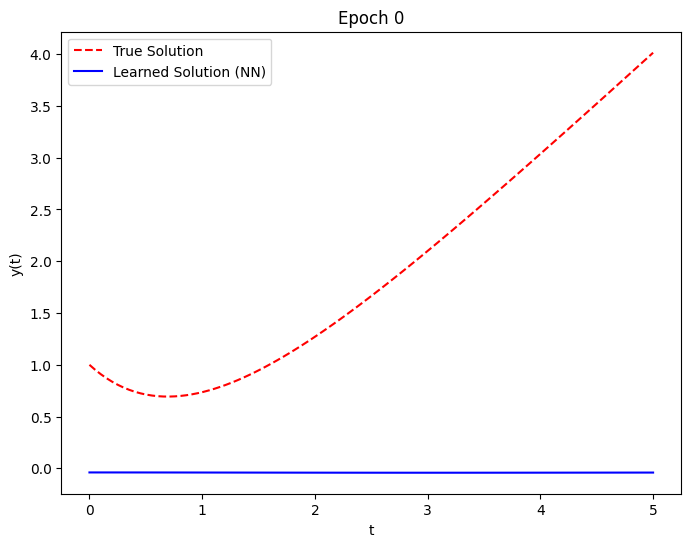

Epoch 10, Test Loss: 1.070033311843872


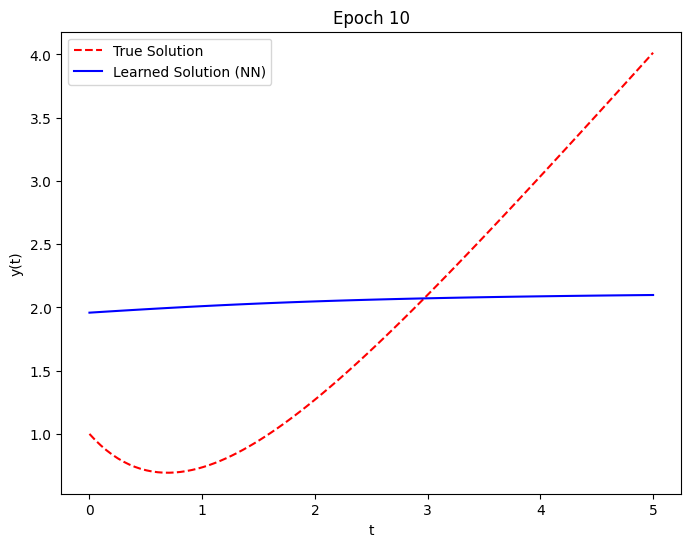

Epoch 20, Test Loss: 0.9689446091651917


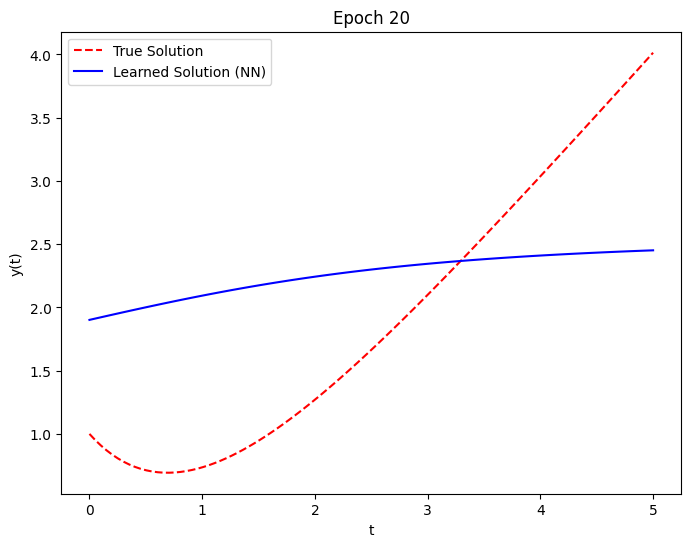

Epoch 30, Test Loss: 0.6645448803901672


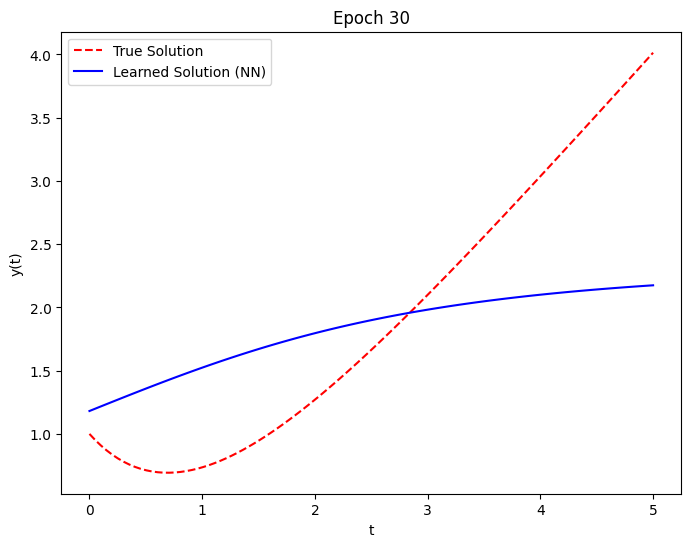

Epoch 40, Test Loss: 0.5255304574966431


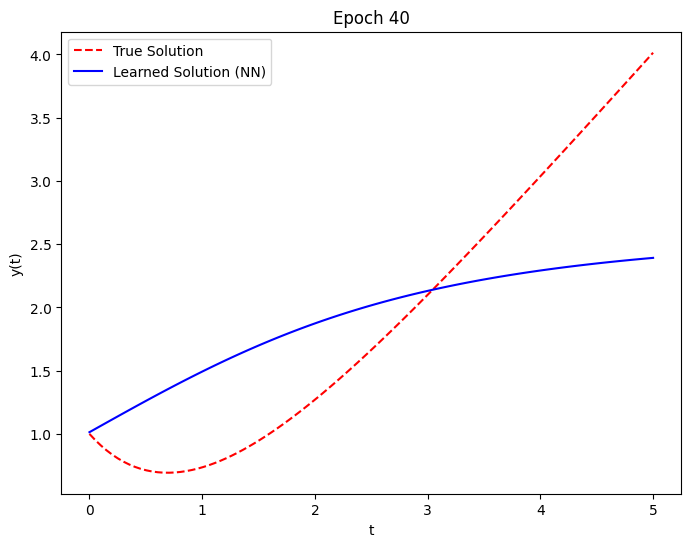

Epoch 50, Test Loss: 0.6159057021141052


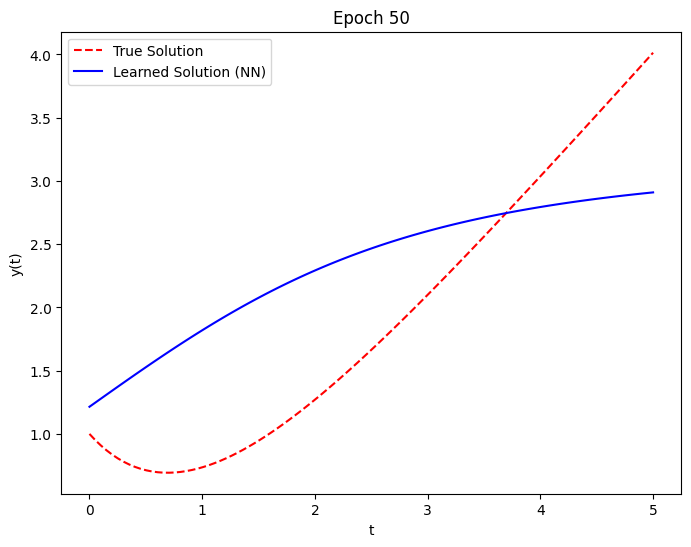

Epoch 60, Test Loss: 0.4235494136810303


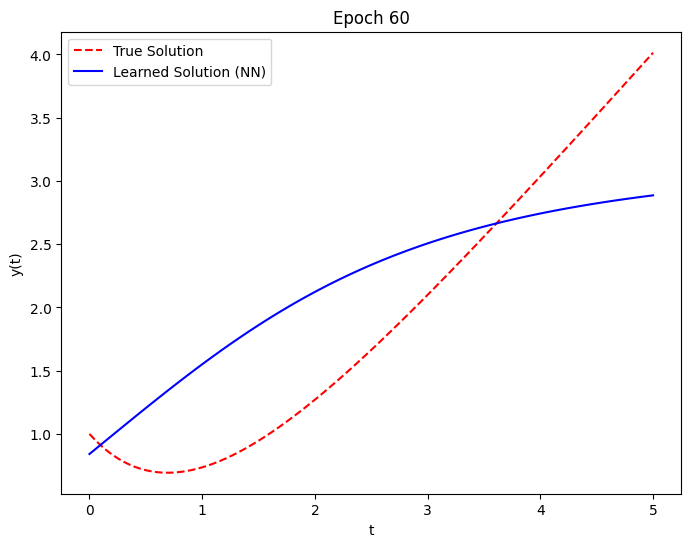

Epoch 70, Test Loss: 0.38052070140838623


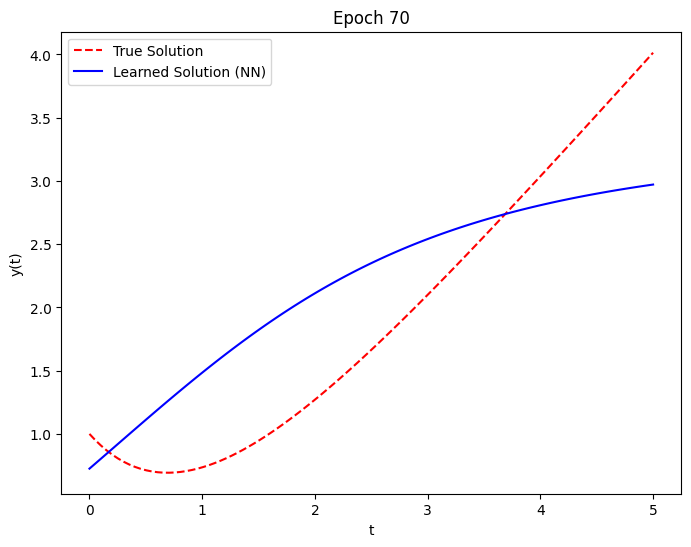

Epoch 80, Test Loss: 0.4325176179409027


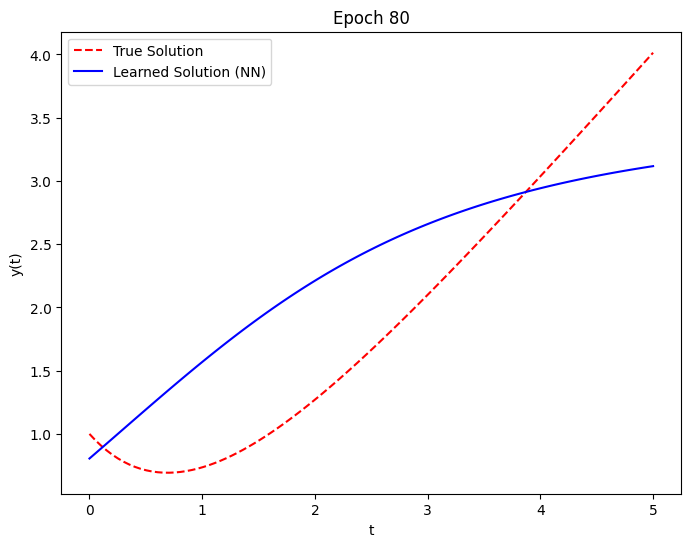

Epoch 90, Test Loss: 0.3275725245475769


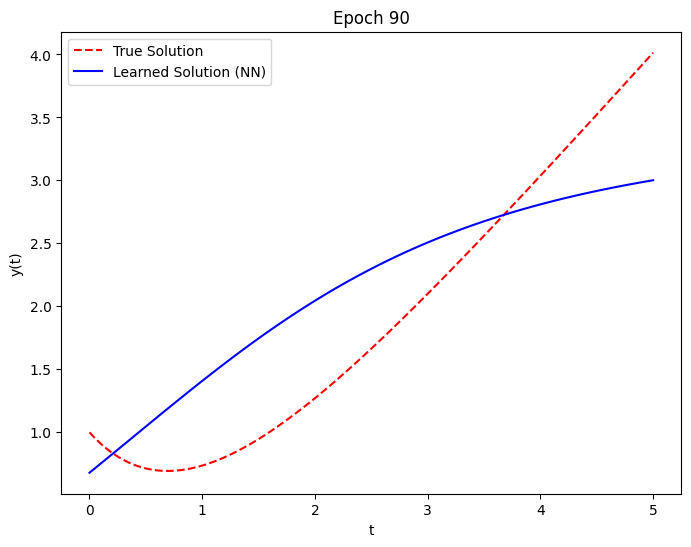

Epoch 100, Test Loss: 0.42907172441482544


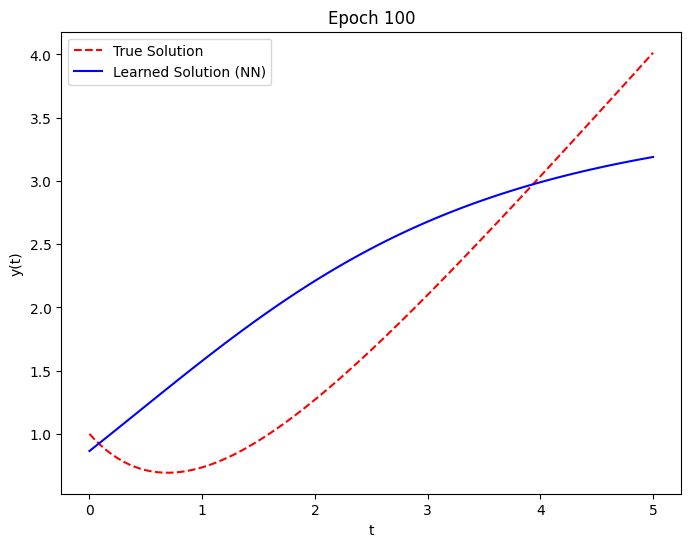

Epoch 110, Test Loss: 0.2630541920661926


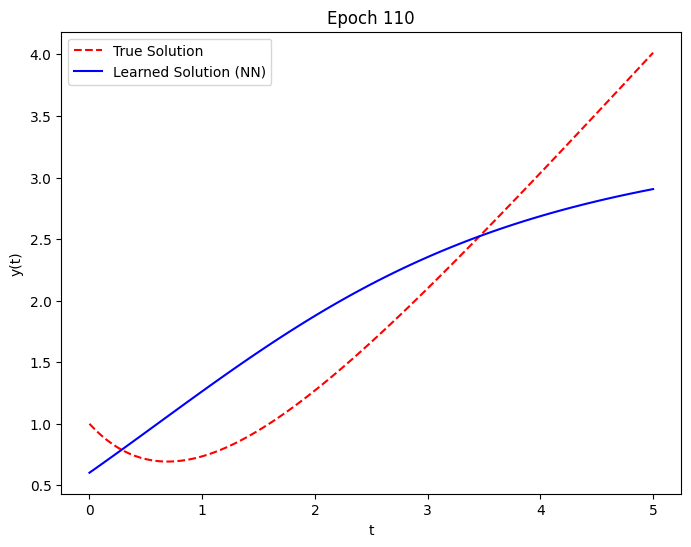

Epoch 120, Test Loss: 0.4185293912887573


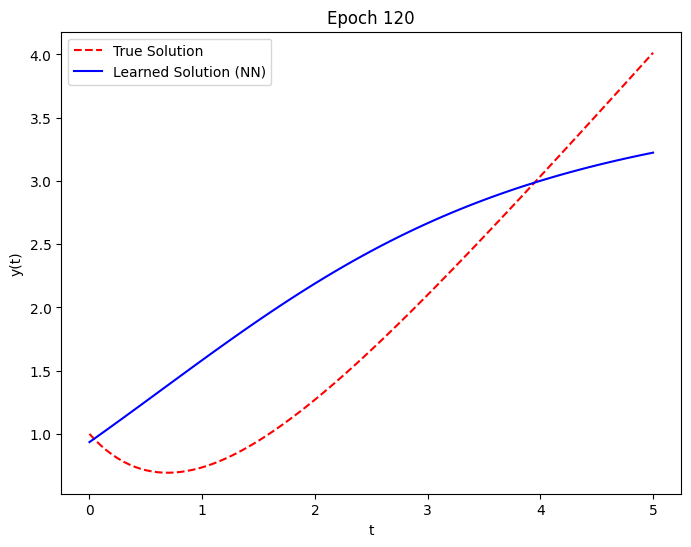

Epoch 130, Test Loss: 0.24237965047359467


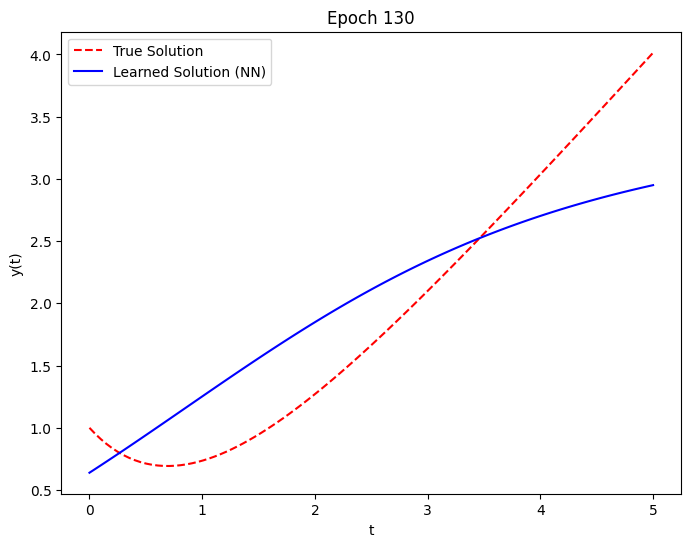

Epoch 140, Test Loss: 0.3154577314853668


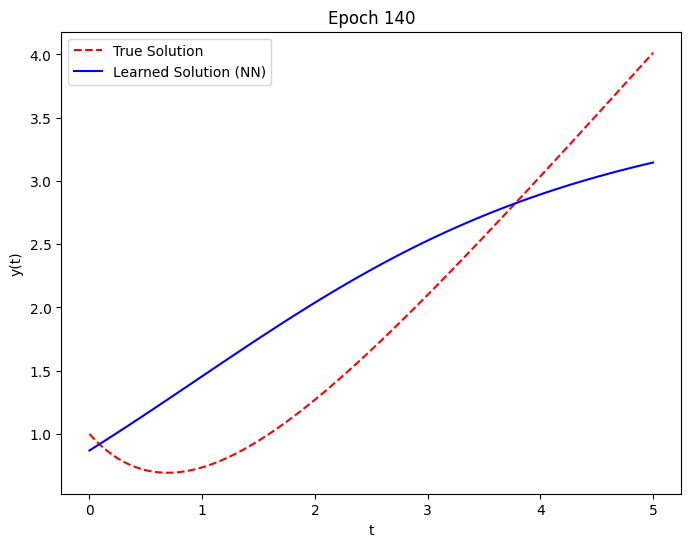

Epoch 150, Test Loss: 0.28752943873405457


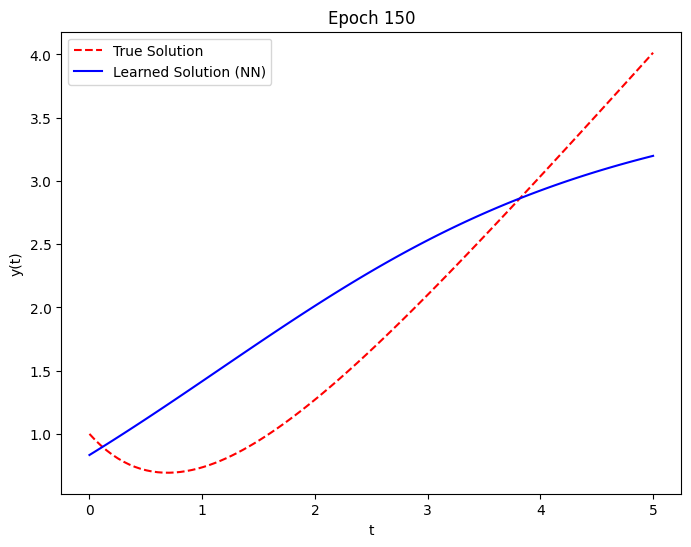

Epoch 160, Test Loss: 0.2488478124141693


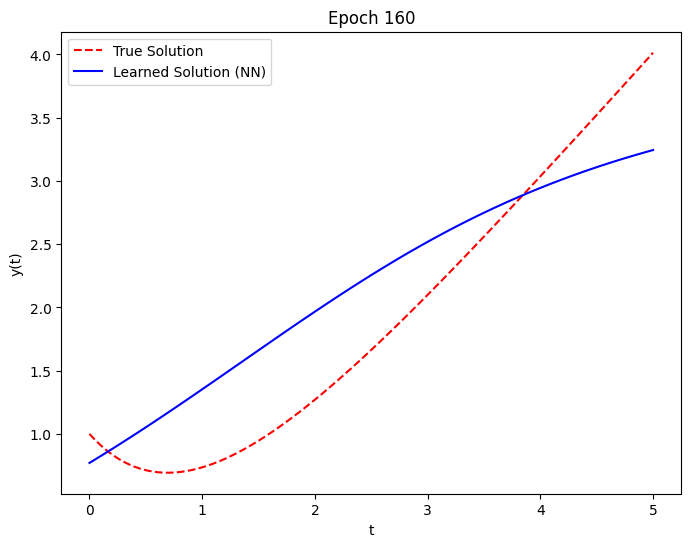

Epoch 170, Test Loss: 0.24502837657928467


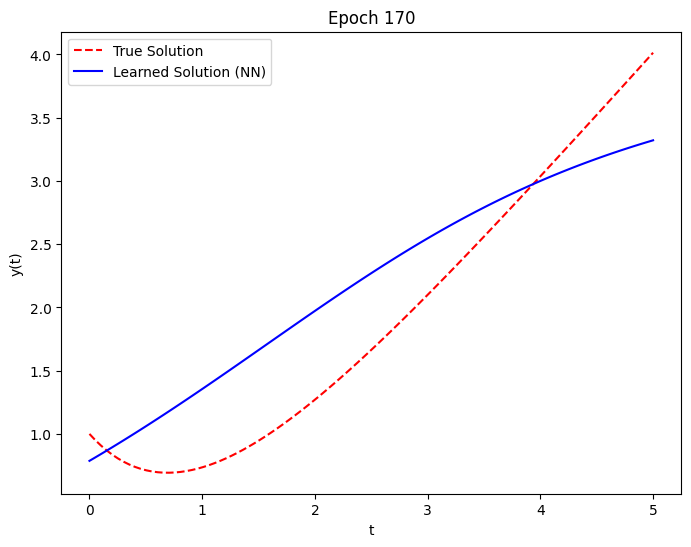

Epoch 180, Test Loss: 0.22558380663394928


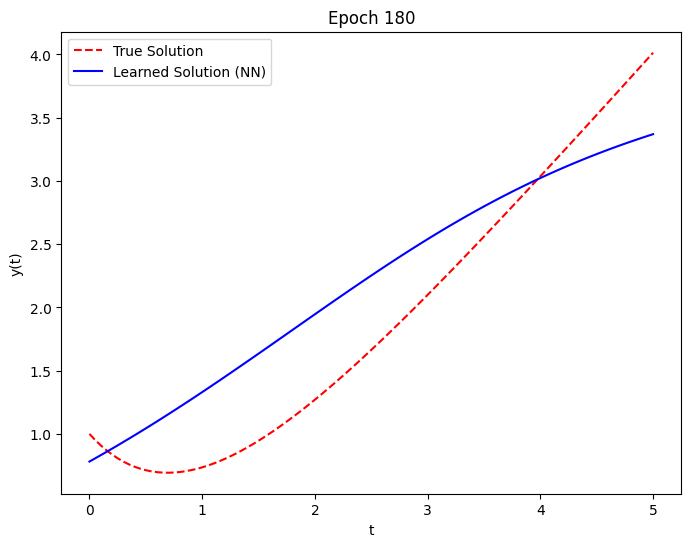

Epoch 190, Test Loss: 0.20072229206562042


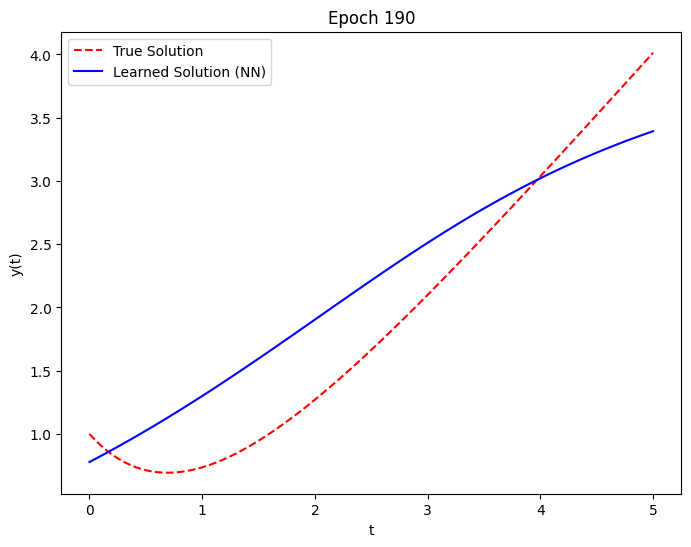

Epoch 200, Test Loss: 0.2627188265323639


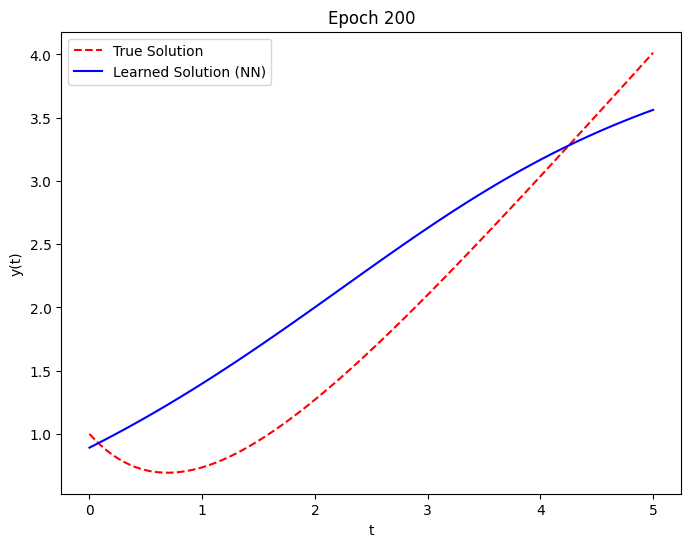

Epoch 210, Test Loss: 0.11516138166189194


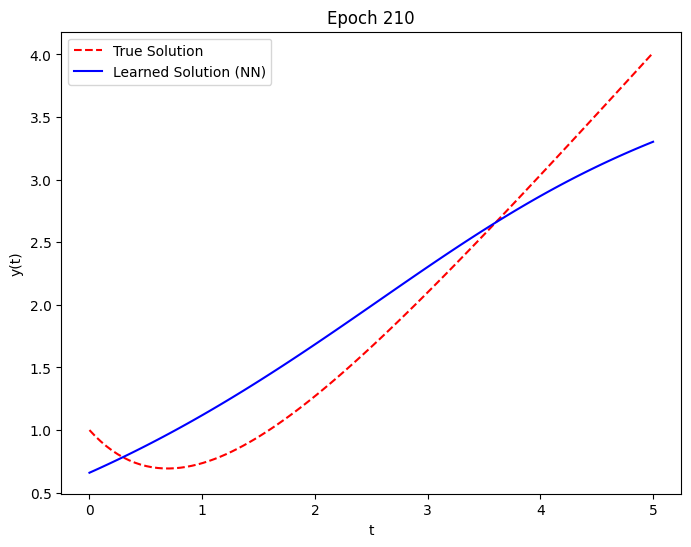

Epoch 220, Test Loss: 0.18787525594234467


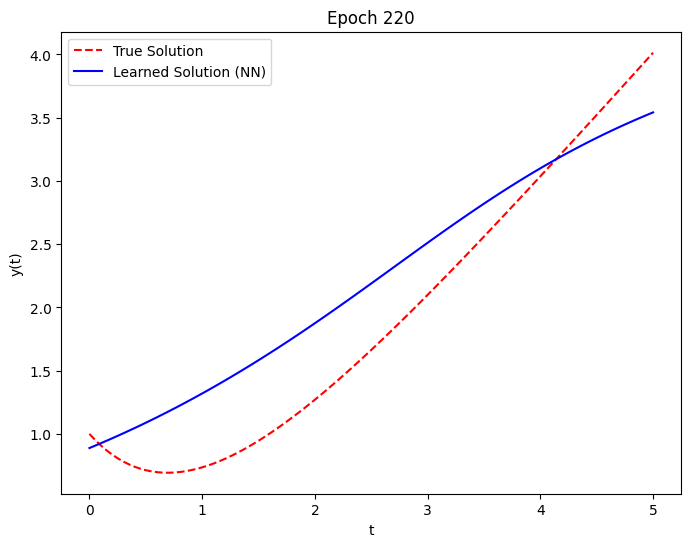

Epoch 230, Test Loss: 0.11772054433822632


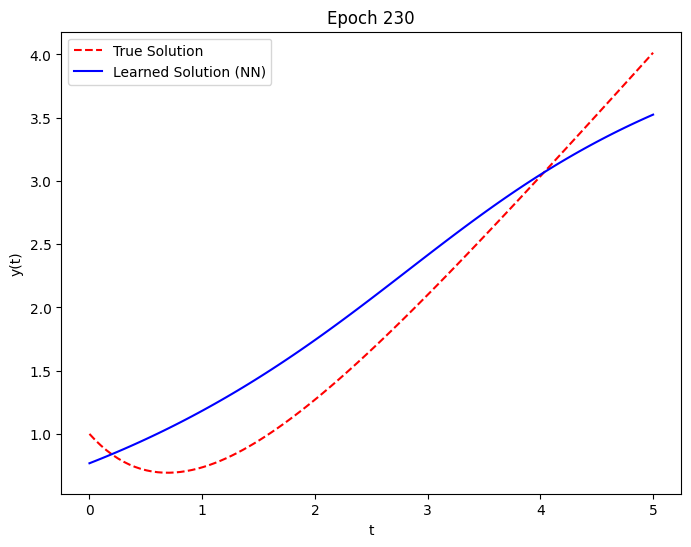

Epoch 240, Test Loss: 0.13030345737934113


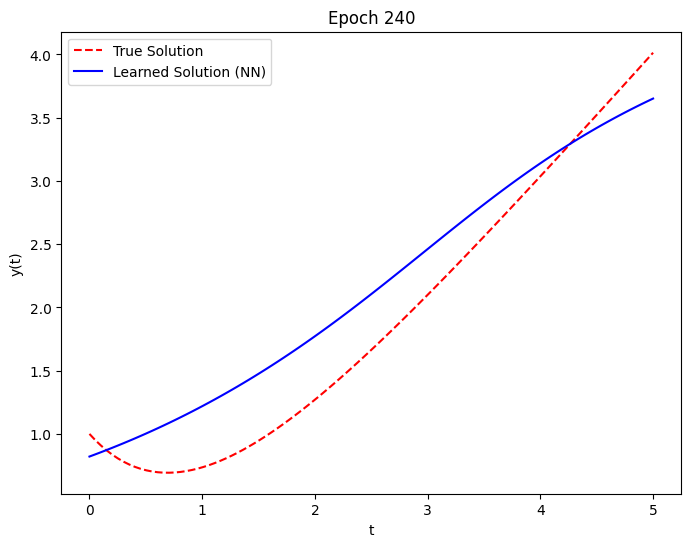

Epoch 250, Test Loss: 0.08552057296037674


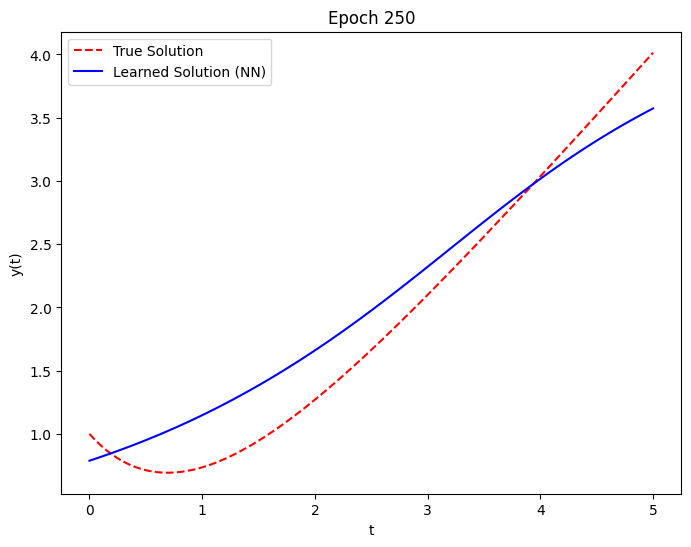

Epoch 260, Test Loss: 0.10453237593173981


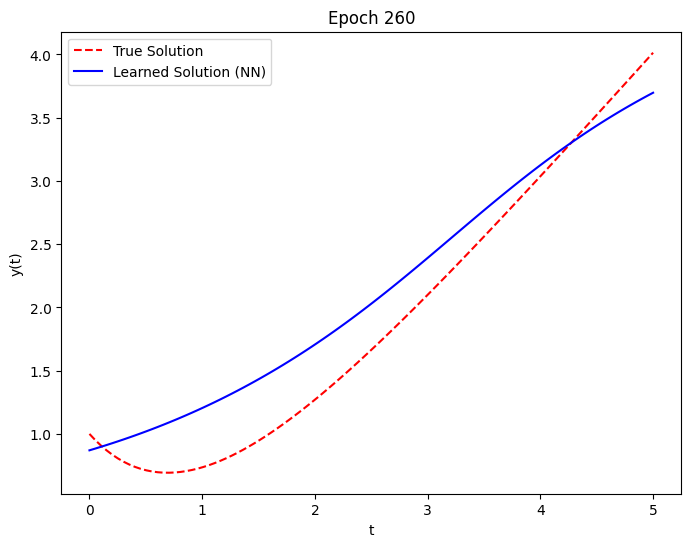

Epoch 270, Test Loss: 0.06945104897022247


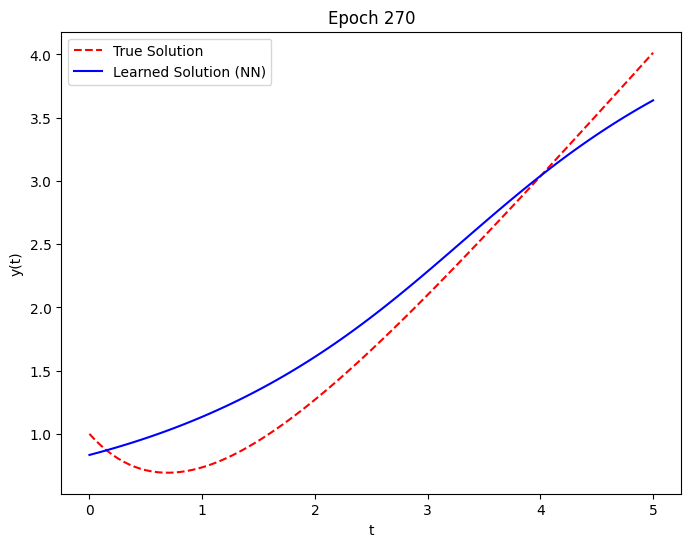

Epoch 280, Test Loss: 0.06658885627985


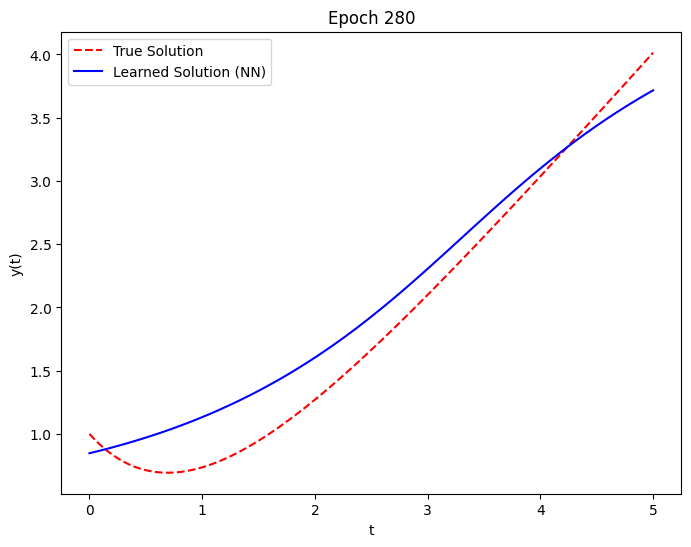

Epoch 290, Test Loss: 0.053983334451913834


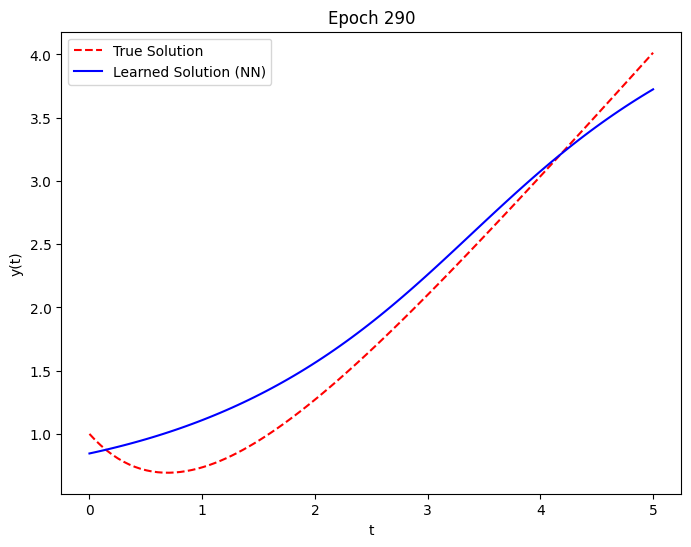

Epoch 300, Test Loss: 0.05615104362368584


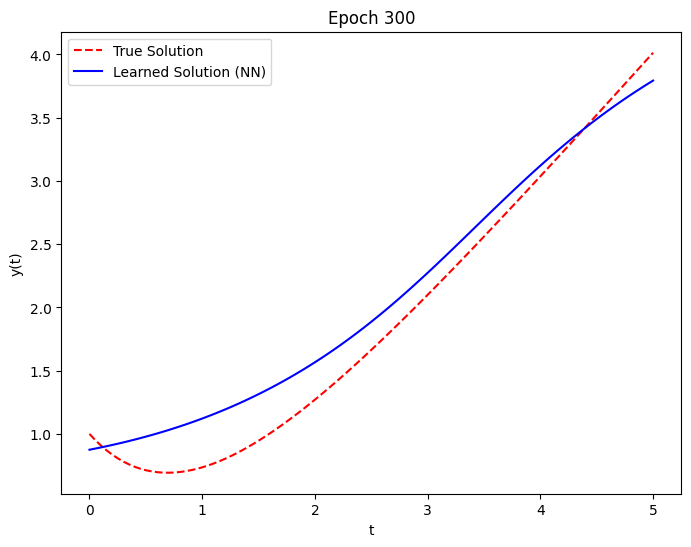

Epoch 310, Test Loss: 0.027861809358000755


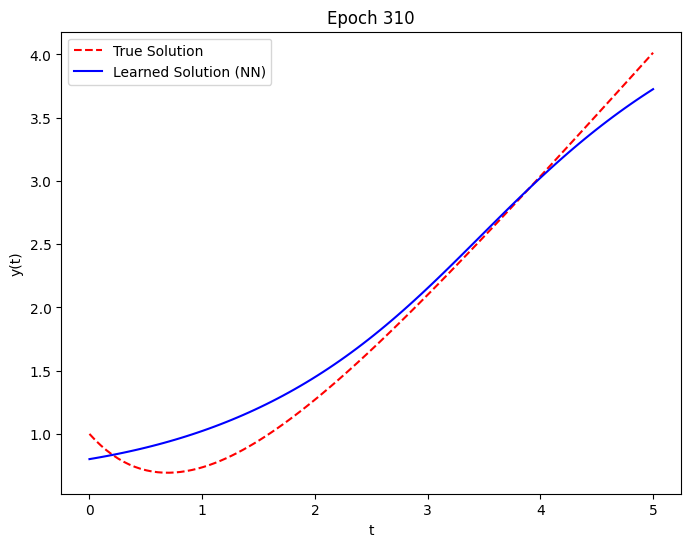

Epoch 320, Test Loss: 0.04011491686105728


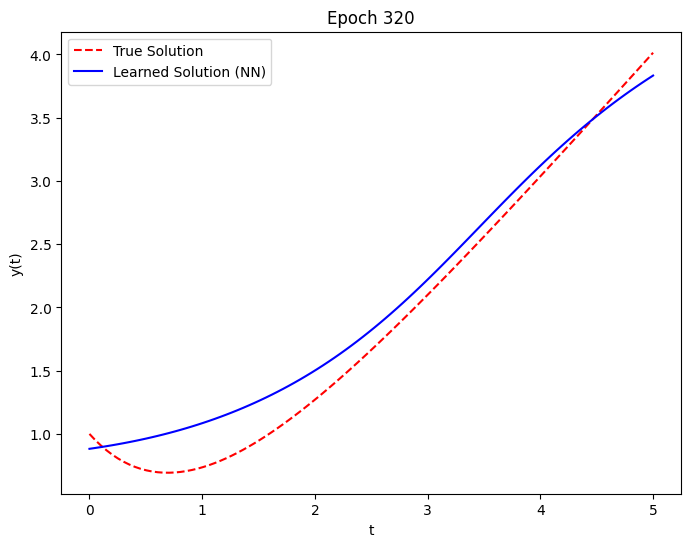

Epoch 330, Test Loss: 0.029052723199129105


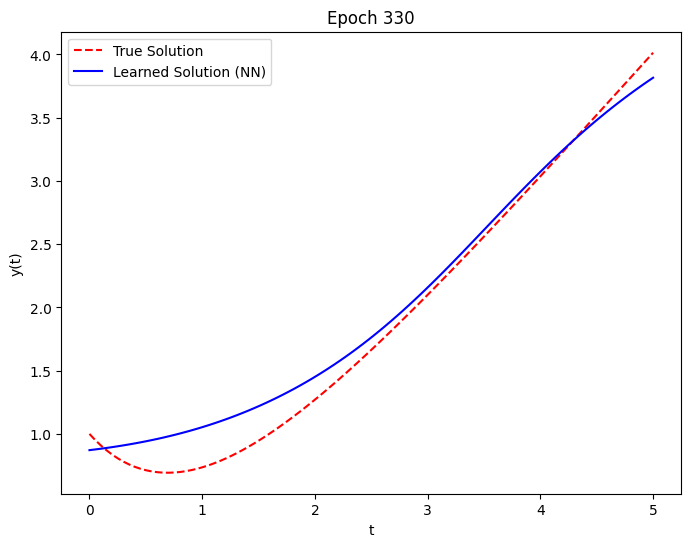

Epoch 340, Test Loss: 0.03334421291947365


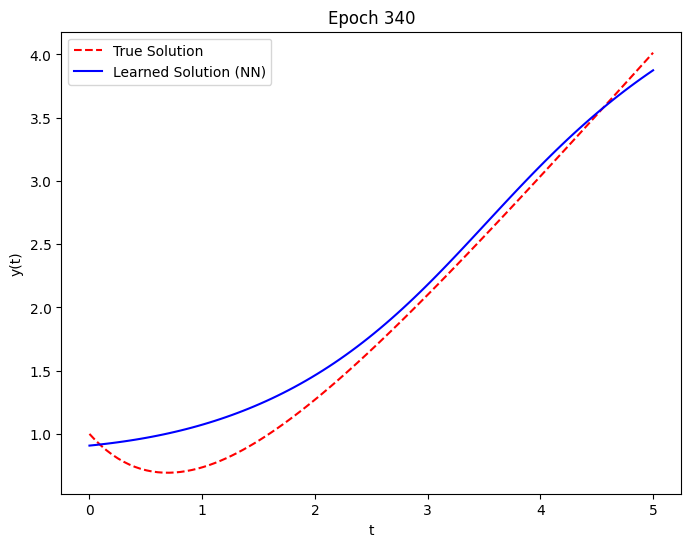

Epoch 350, Test Loss: 0.024910083040595055


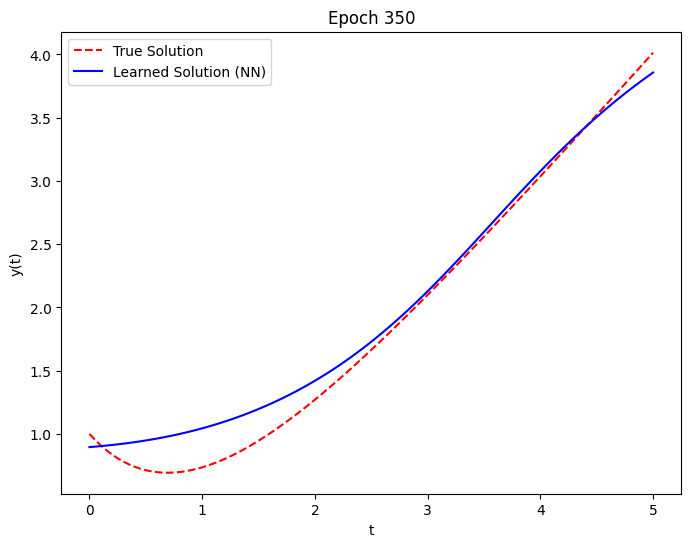

Epoch 360, Test Loss: 0.0178526584059


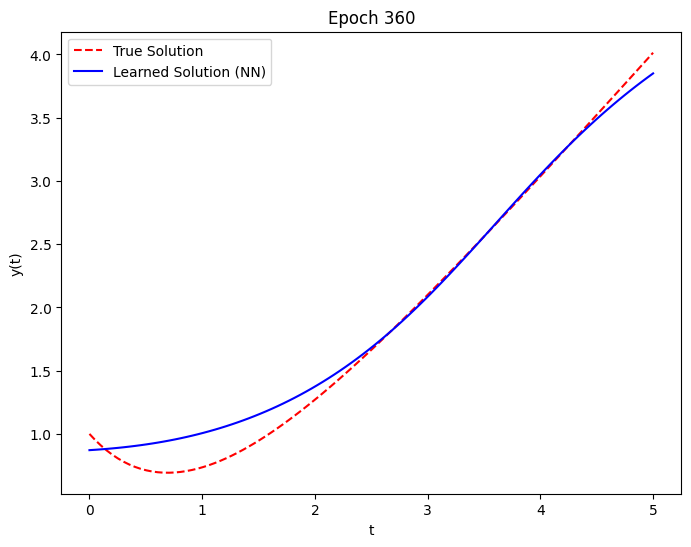

Epoch 370, Test Loss: 0.029195141047239304


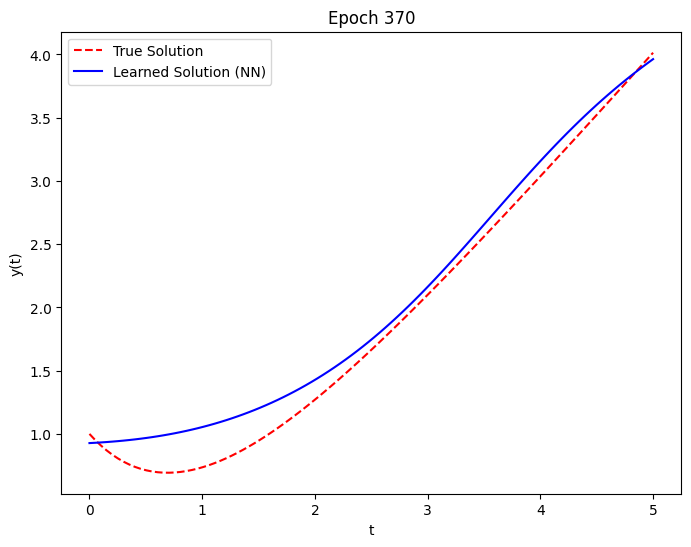

Epoch 380, Test Loss: 0.017710931599140167


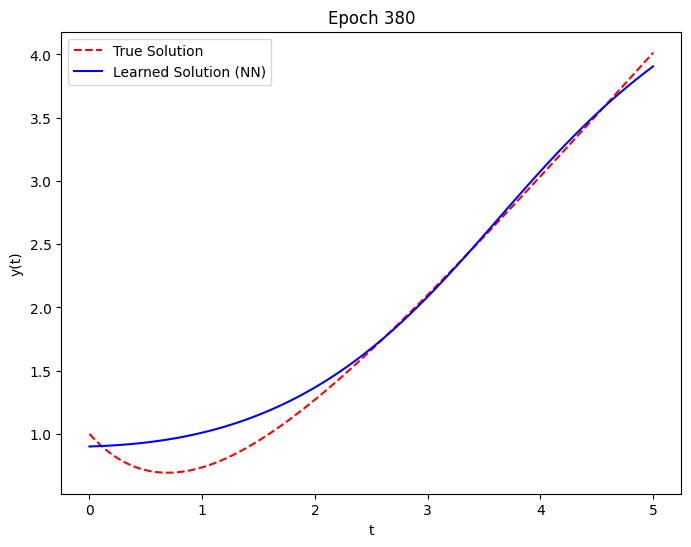

Epoch 390, Test Loss: 0.016106421127915382


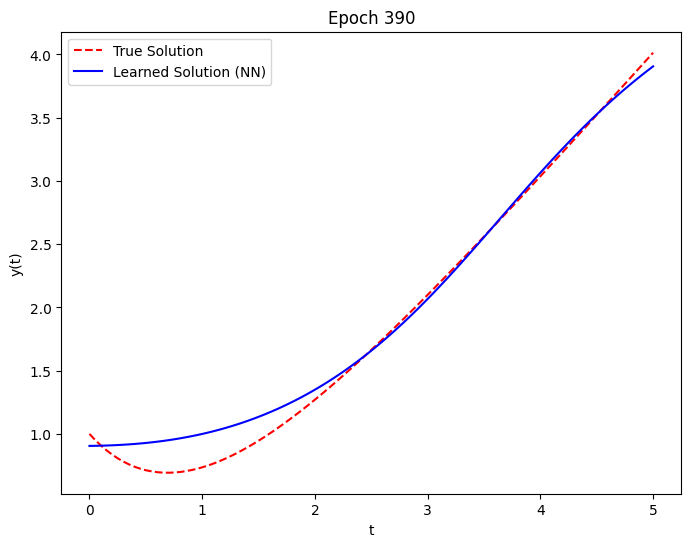

Epoch 400, Test Loss: 0.025631161406636238


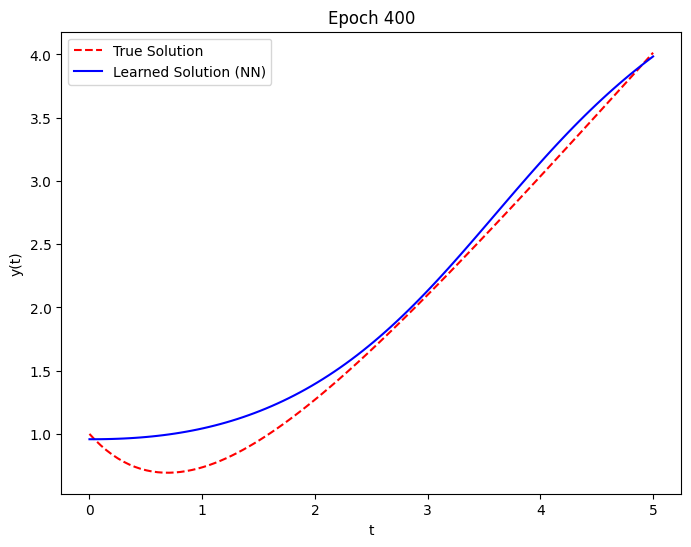

Epoch 410, Test Loss: 0.00985689740628004


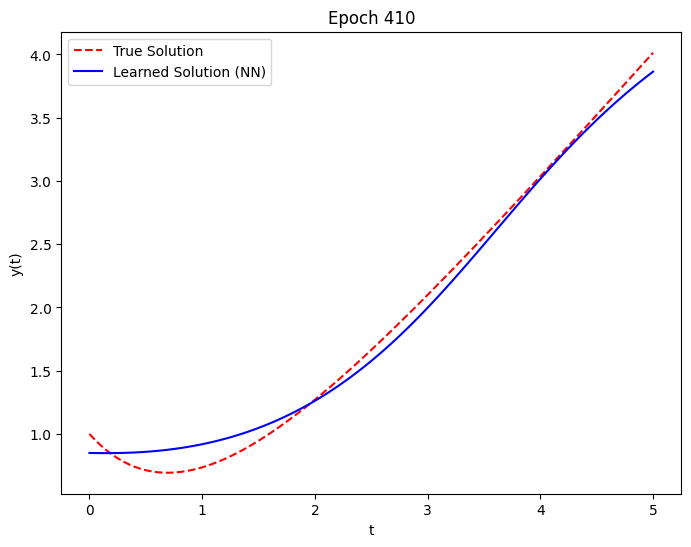

Epoch 420, Test Loss: 0.016068510711193085


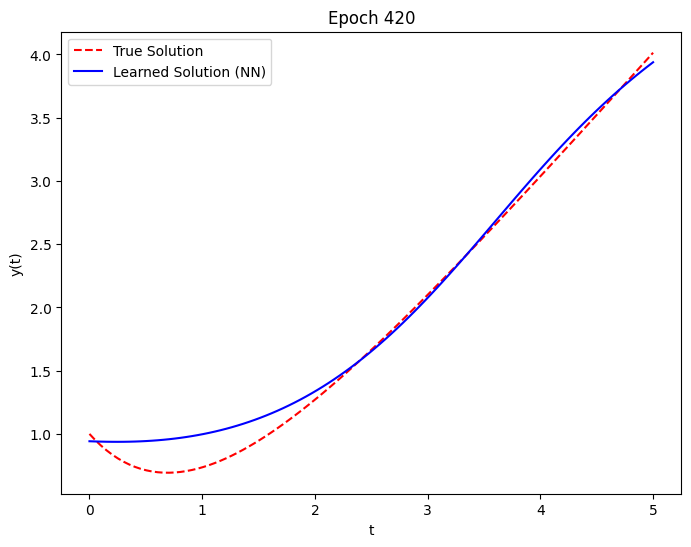

Epoch 430, Test Loss: 0.016284938901662827


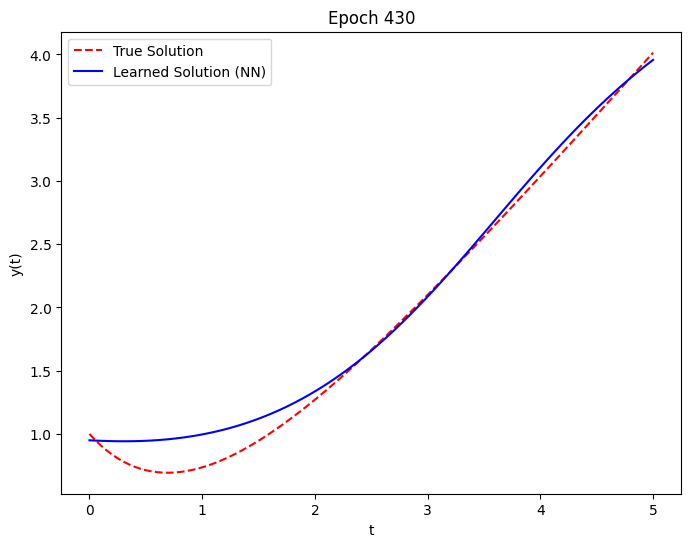

Epoch 440, Test Loss: 0.007177114021033049


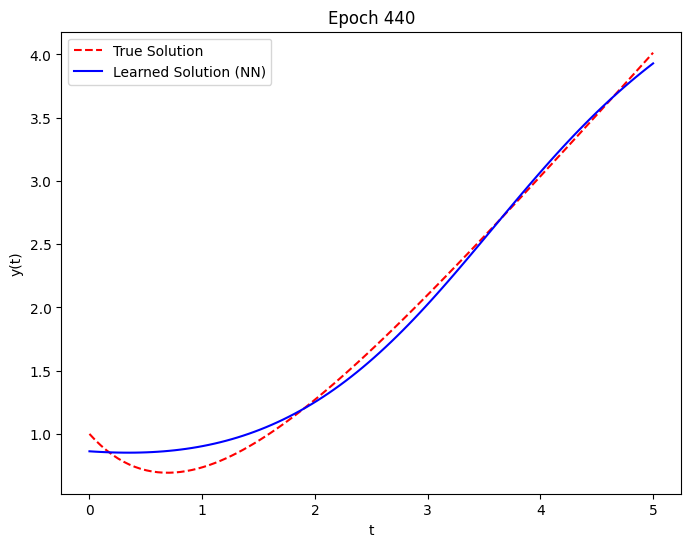

Epoch 450, Test Loss: 0.01796671748161316


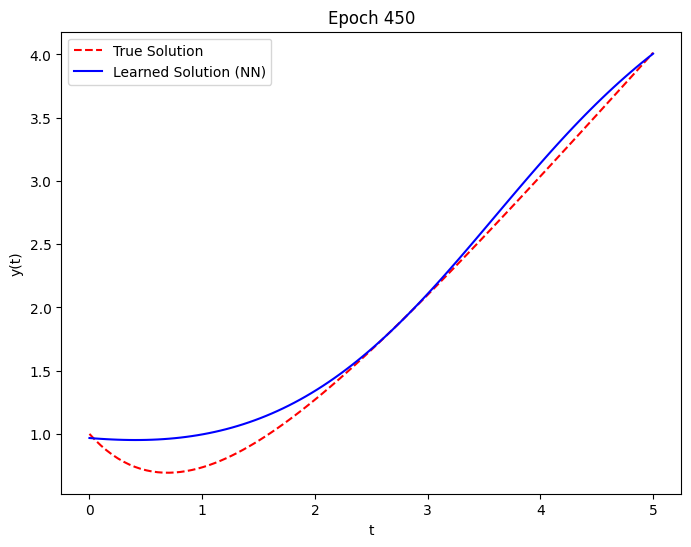

Epoch 460, Test Loss: 0.012831432744860649


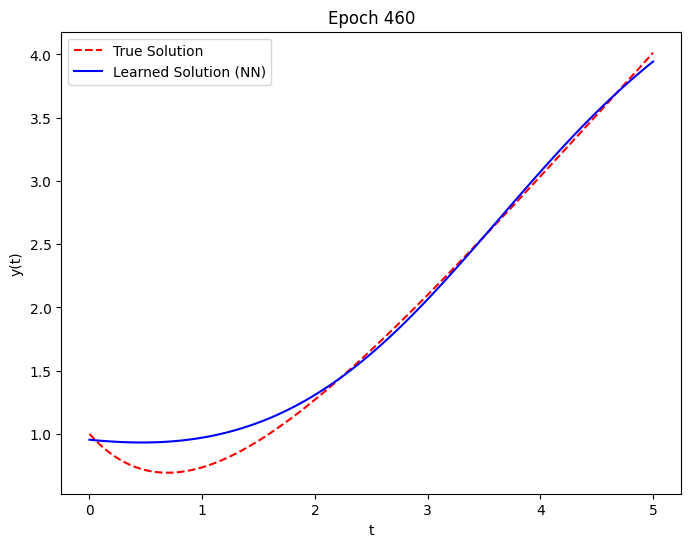

Epoch 470, Test Loss: 0.008094039745628834


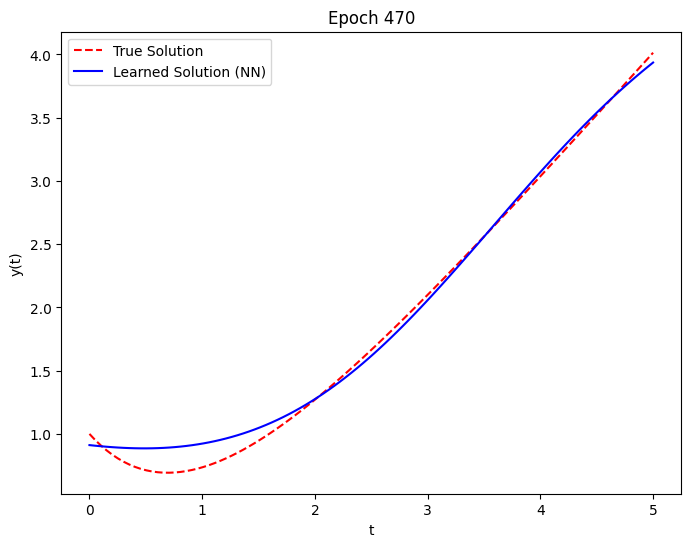

Epoch 480, Test Loss: 0.013079850934445858


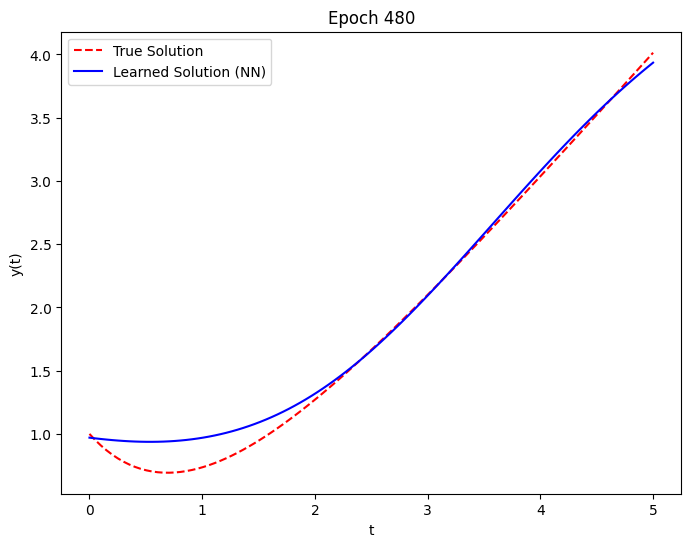

Epoch 490, Test Loss: 0.008245313540101051


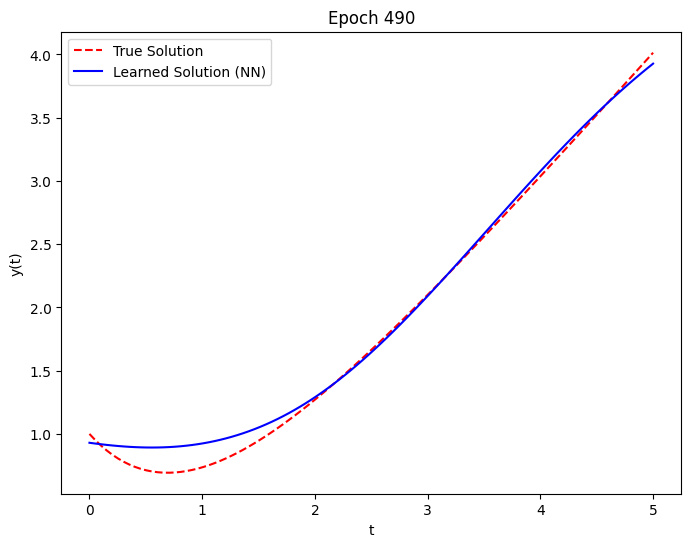

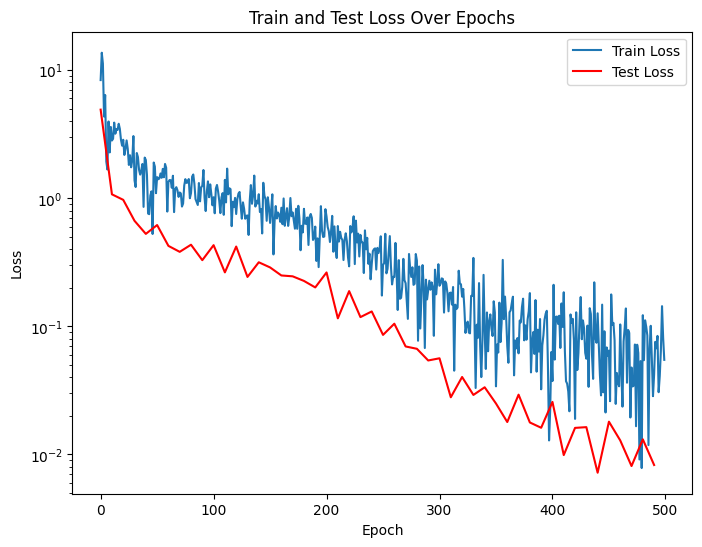

In [ ]:
# Initialize the model
set_seed(1)
model = NeuralNet()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# Run the training
num_epochs, train_losses, test_losses = train_ode_solver(model, optimizer)
plot_losses(num_epochs, train_losses, test_losses)

### Running with several seeds

To check robustness

In [ ]:
def run_multiple_seeds(seeds=[1, 2, 3, 4, 5], num_epochs=500):
    all_train_losses = []
    all_test_losses = []

    for s in seeds:
        print(f"Training with seed {s}...")
        # Set the seed for reproducibility
        set_seed(s)

        # Initialize a new model and optimizer for each seed
        model = NeuralNet()
        optimizer = optim.Adam(model.parameters(), lr=0.001)

        # Train the model
        # We can temporarily suppress plotting during intermediate training epochs to keep the output clean
        # (We use a simple trick of overriding or ignoring intermediate displays inside train_ode_solver if desired,
        # but running as-is is also fine)
        # TODO

        all_train_losses.append(train_losses)
        all_test_losses.append(test_losses)

    # Convert lists to numpy arrays: shape (num_seeds, num_epochs)
    all_train_losses = np.array(all_train_losses)
    all_test_losses = np.array(all_test_losses)

    return epochs, all_train_losses, all_test_losses

def plot_aggregated_losses(num_epochs, all_train_losses, all_test_losses):
    # Compute mean and standard deviation
    mean_train = np.mean(all_train_losses, axis=0)
    std_train = np.std(all_train_losses, axis=0)

    mean_test = np.mean(all_test_losses, axis=0)
    std_test = np.std(all_test_losses, axis=0)

    epochs_train = np.arange(num_epochs)
    epochs_test = np.arange(0, num_epochs, 10)

    plt.figure(figsize=(10, 6))

    # Plot Train Loss Mean + Shaded Std
    plt.semilogy(epochs_train, mean_train, label='Mean Train Loss', color='blue')
    plt.fill_between(
        epochs_train,
        np.clip(mean_train - std_train, 1e-8, None), # Prevent non-positive values for log scale
        mean_train + std_train,
        color='blue',
        alpha=0.2,
        label='Train Loss ± 1 Std'
    )

    # Plot Test Loss Mean + Shaded Std
    plt.semilogy(epochs_test, mean_test, label='Mean Test Loss', color='red')
    plt.fill_between(
        epochs_test,
        np.clip(mean_test - std_test, 1e-8, None),
        mean_test + std_test,
        color='red',
        alpha=0.2,
        label='Test Loss ± 1 Std'
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train and Test Loss Over 5 Seeds (Mean ± Std Dev)")
    plt.legend()
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.show()

Training with seed 1...
Epoch 0, Test Loss: 4.9041643142700195
Epoch 10, Test Loss: 1.070033311843872
Epoch 20, Test Loss: 0.9689446091651917
Epoch 30, Test Loss: 0.6645448803901672
Epoch 40, Test Loss: 0.5255304574966431
Epoch 50, Test Loss: 0.6159057021141052
Epoch 60, Test Loss: 0.4235494136810303
Epoch 70, Test Loss: 0.38052070140838623
Epoch 80, Test Loss: 0.4325176179409027
Epoch 90, Test Loss: 0.3275725245475769
Epoch 100, Test Loss: 0.42907172441482544
Epoch 110, Test Loss: 0.2630541920661926
Epoch 120, Test Loss: 0.4185293912887573
Epoch 130, Test Loss: 0.24237965047359467
Epoch 140, Test Loss: 0.3154577314853668
Epoch 150, Test Loss: 0.28752943873405457
Epoch 160, Test Loss: 0.2488478124141693
Epoch 170, Test Loss: 0.24502837657928467
Epoch 180, Test Loss: 0.22558380663394928
Epoch 190, Test Loss: 0.20072229206562042
Epoch 200, Test Loss: 0.2627188265323639
Epoch 210, Test Loss: 0.11516138166189194
Epoch 220, Test Loss: 0.18787525594234467
Epoch 230, Test Loss: 0.117720544338

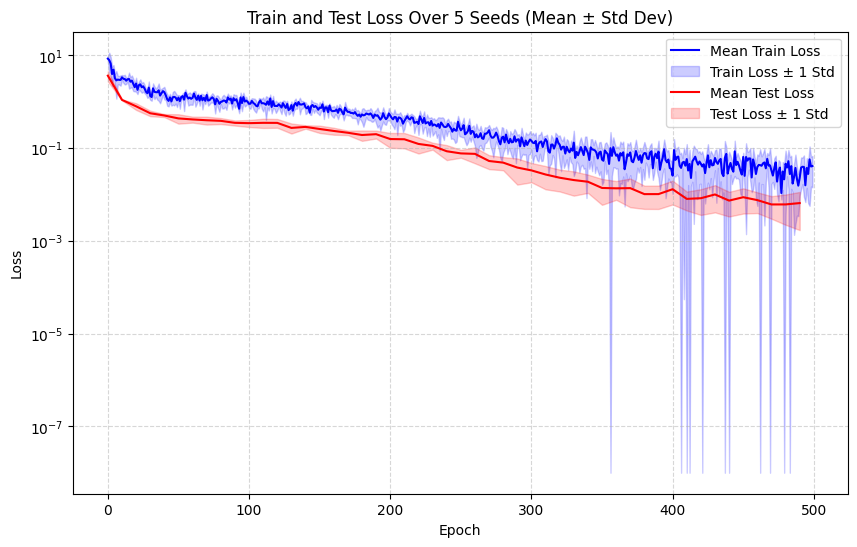

In [ ]:
# Execute the multi-seed experiment and plot the results
num_epochs_param = 500
seeds_to_test = [1, 2, 3, 4, 5]

epochs, all_train, all_test = run_multiple_seeds(seeds=seeds_to_test, num_epochs=num_epochs_param)
plot_aggregated_losses(epochs, all_train, all_test)

### Larger weight for IC

 With larger weight for initial condition: the NN gets stuck in a bad local minimum.

In [ ]:
# Main function to train the model
def train_ode_solver_weight(model,
                            optimizer,
                            T = 5.0,
                            num_epochs = 500,
                            batch_size = 10,
                            weight_IC=1):
    # Create a testing set of 100 points sampled uniformly from [0, T]
    t_test = torch.linspace(0, T, 100).unsqueeze(1)
    y_test_true = true_solution(t_test).detach()

    # Lists to store losses
    train_losses = []
    test_losses = []

    # Training loop
    for epoch in range(num_epochs):
        model.train()

        # Sample minibatch of time points uniformly in [0, T]
        t_batch = T * torch.rand(batch_size, 1)

        # Compute the total loss: ODE residual loss + weight * initial condition loss
        # TODO

        # Backpropagation and optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record train loss
        train_losses.append(loss.item())

        # Evaluate the model on the testing set every 10 epochs
        if epoch % 10 == 0:
            model.eval()
            with torch.no_grad():
                y_test_pred = model(t_test)
                test_loss = torch.mean((y_test_pred - y_test_true) ** 2)
                test_losses.append(test_loss.item())
                print(f'Epoch {epoch}, Test Loss: {test_loss.item()}')

                # Plot the true solution and the learned solution by the NN
                plt.figure(figsize=(8, 6))
                plt.plot(t_test.numpy(), y_test_true.numpy(), 'r--', label="True Solution")
                plt.plot(t_test.numpy(), y_test_pred.numpy(), 'b-', label="Learned Solution (NN)")
                plt.legend()
                plt.xlabel("t")
                plt.ylabel("y(t)")
                plt.title(f"Epoch {epoch}")
                plt.show()

    return num_epochs, train_losses, test_losses

Epoch 0, Test Loss: 4.904167175292969


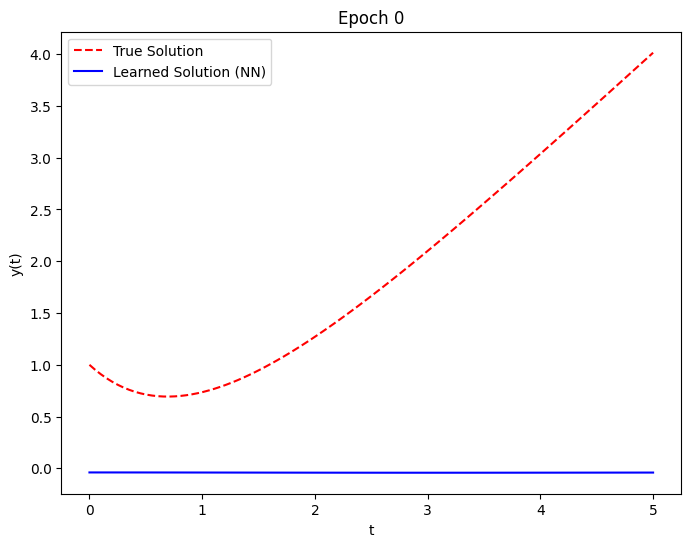

Epoch 10, Test Loss: 1.2222195863723755


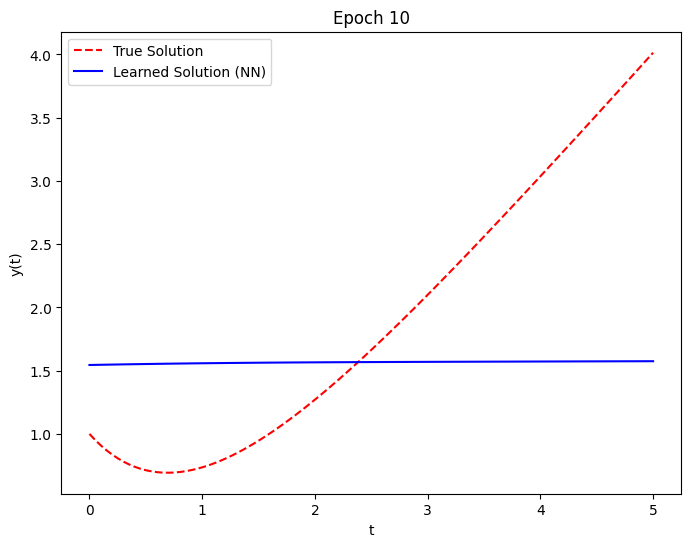

Epoch 20, Test Loss: 2.1425023078918457


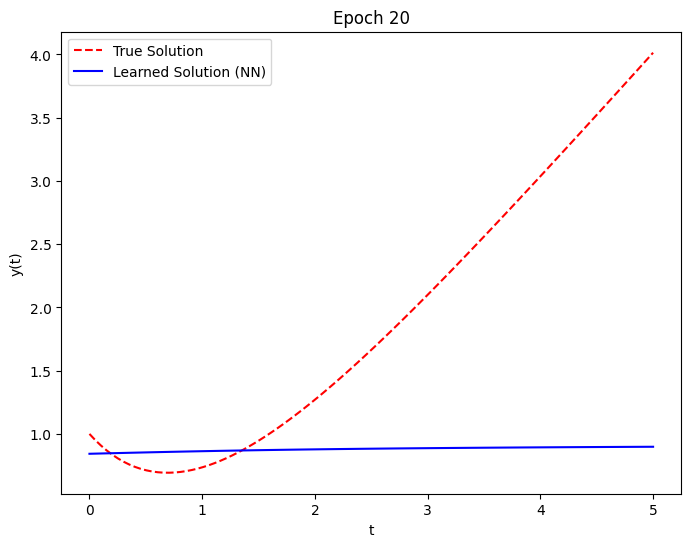

Epoch 30, Test Loss: 1.8254274129867554


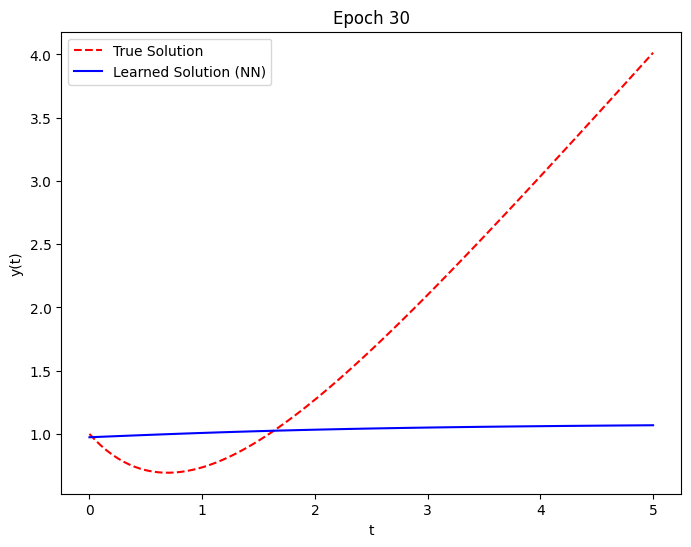

Epoch 40, Test Loss: 1.552992820739746


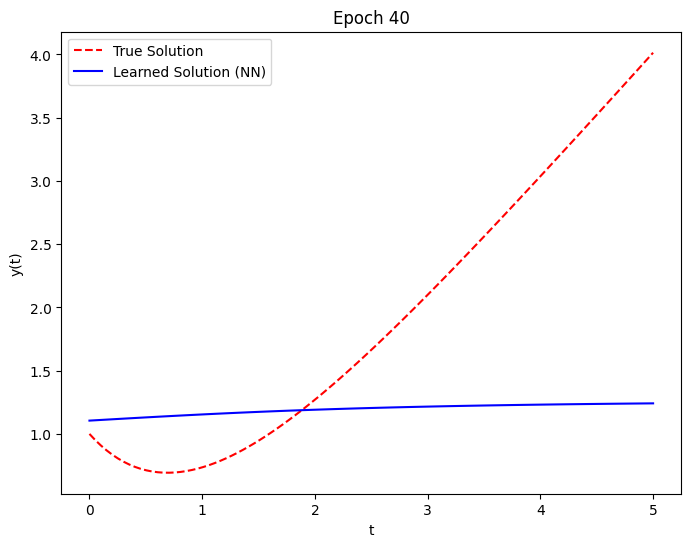

Epoch 50, Test Loss: 1.7280696630477905


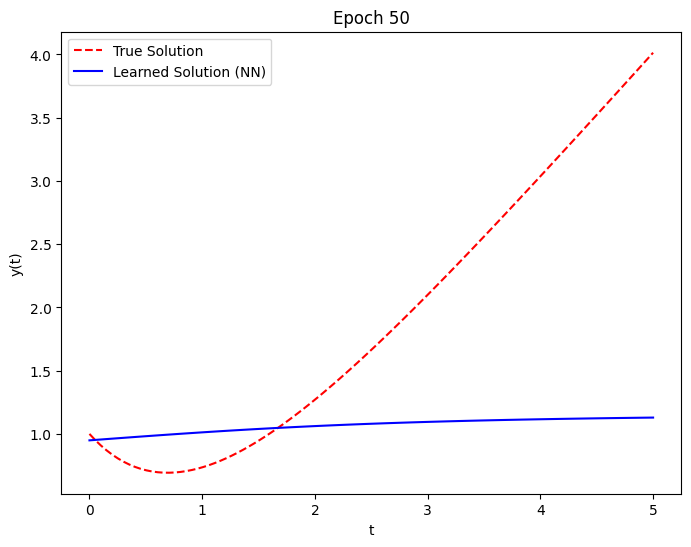

Epoch 60, Test Loss: 1.4986090660095215


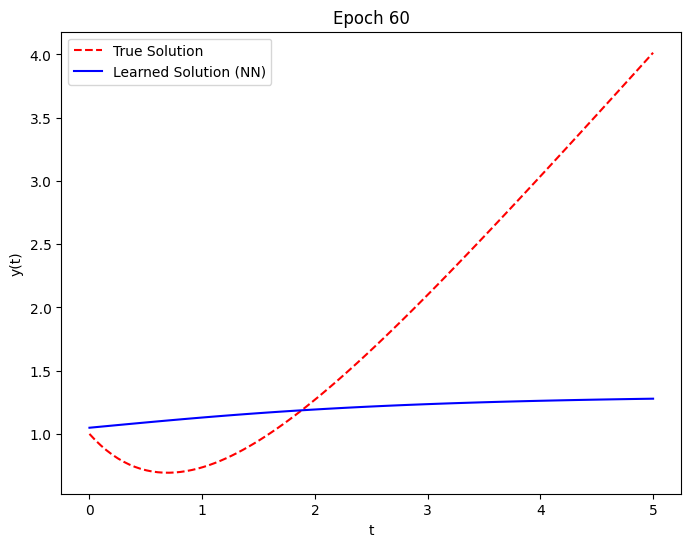

Epoch 70, Test Loss: 1.5056260824203491


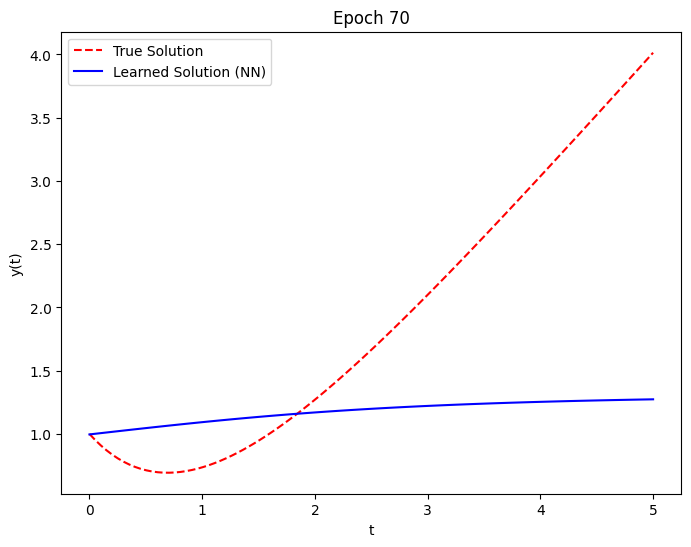

Epoch 80, Test Loss: 1.4038283824920654


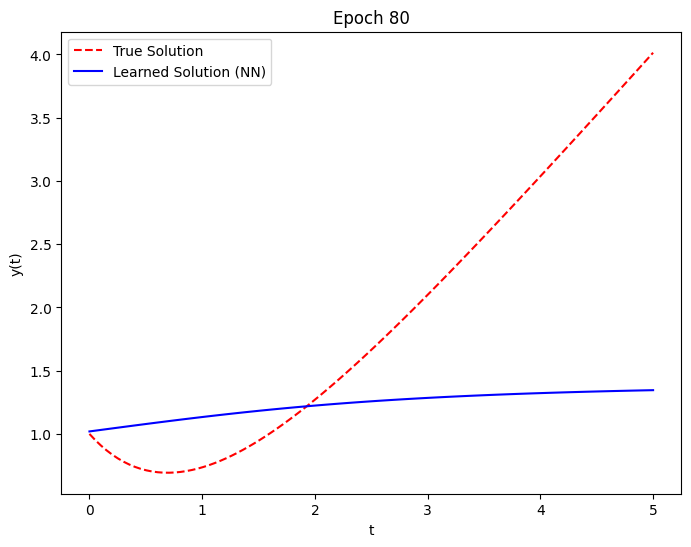

Epoch 90, Test Loss: 1.3586772680282593


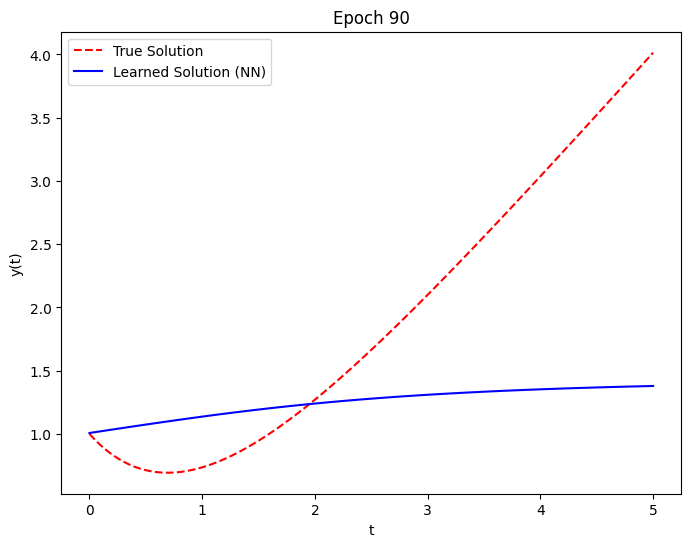

Epoch 100, Test Loss: 1.2840282917022705


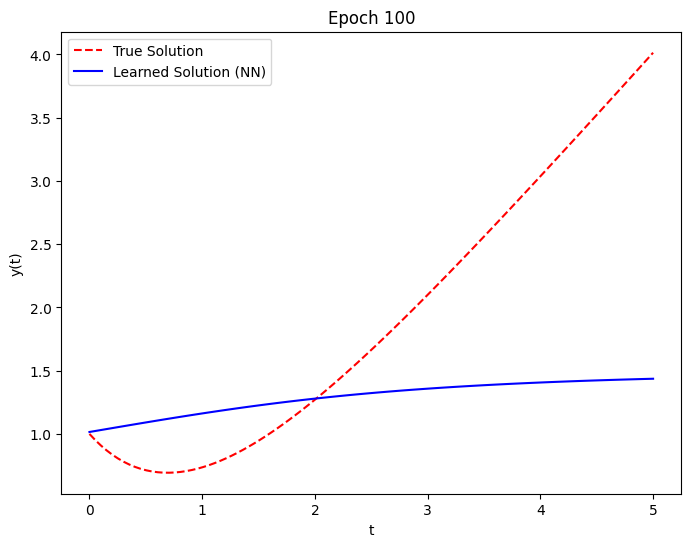

Epoch 110, Test Loss: 1.240591049194336


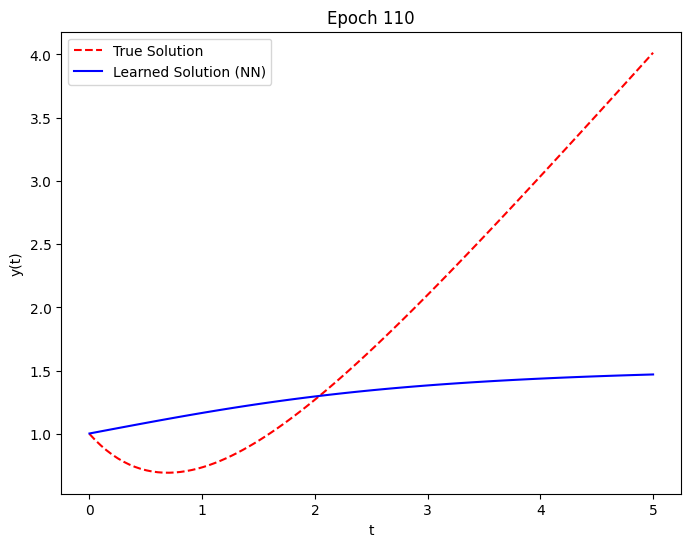

Epoch 120, Test Loss: 1.1666327714920044


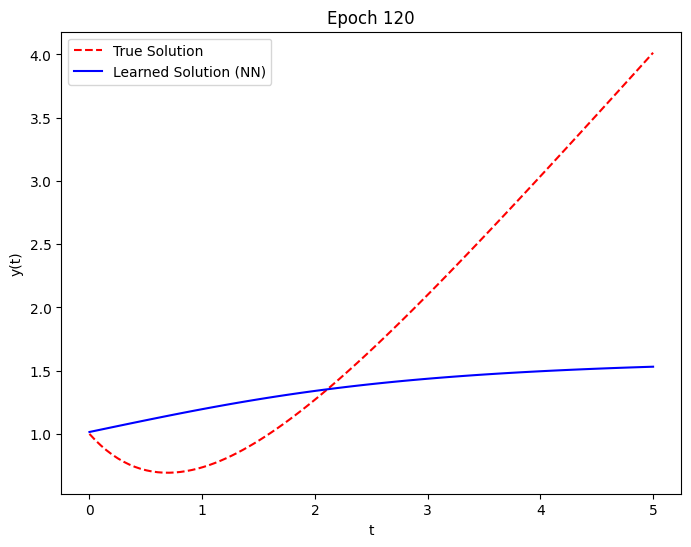

Epoch 130, Test Loss: 1.12527334690094


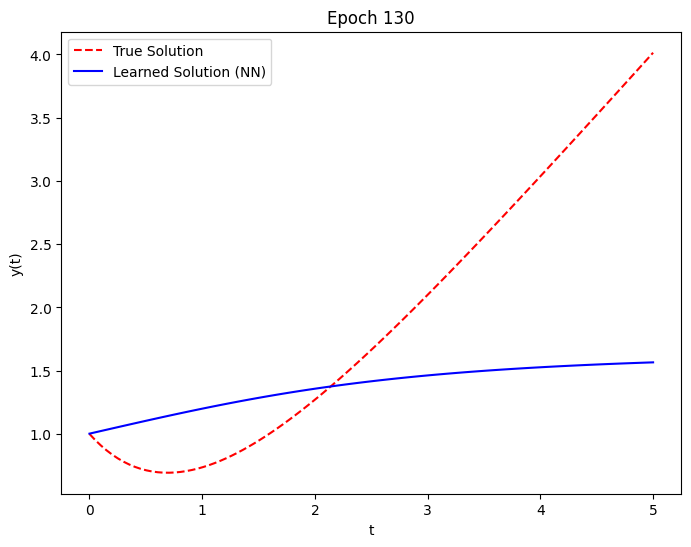

Epoch 140, Test Loss: 1.064037799835205


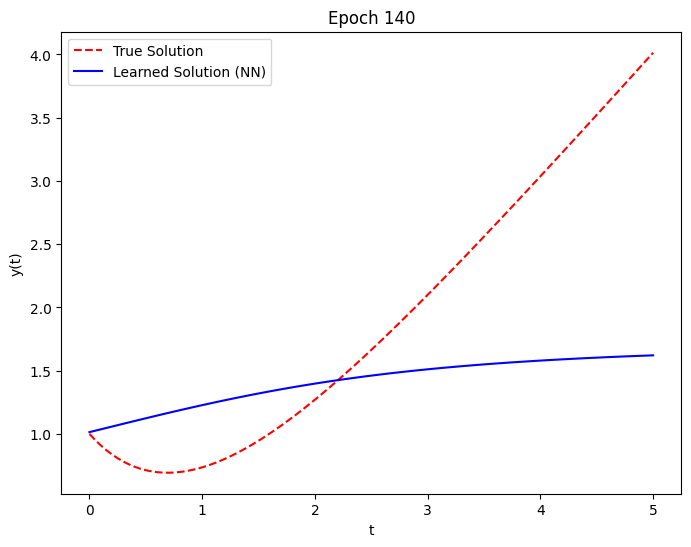

Epoch 150, Test Loss: 1.0219447612762451


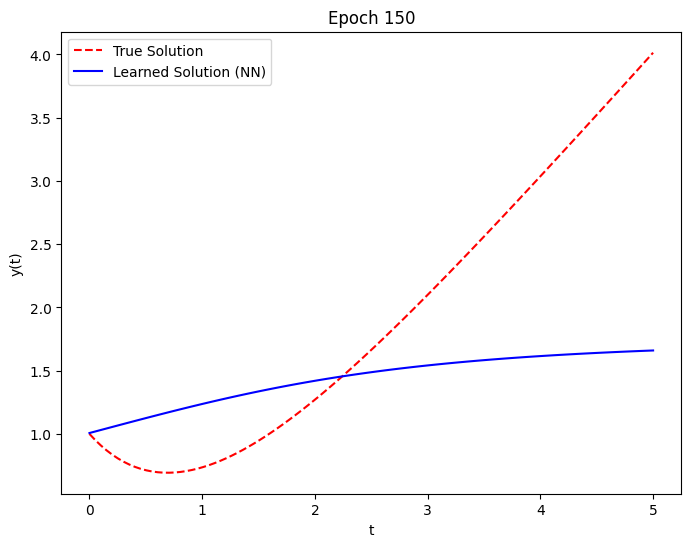

Epoch 160, Test Loss: 0.970704197883606


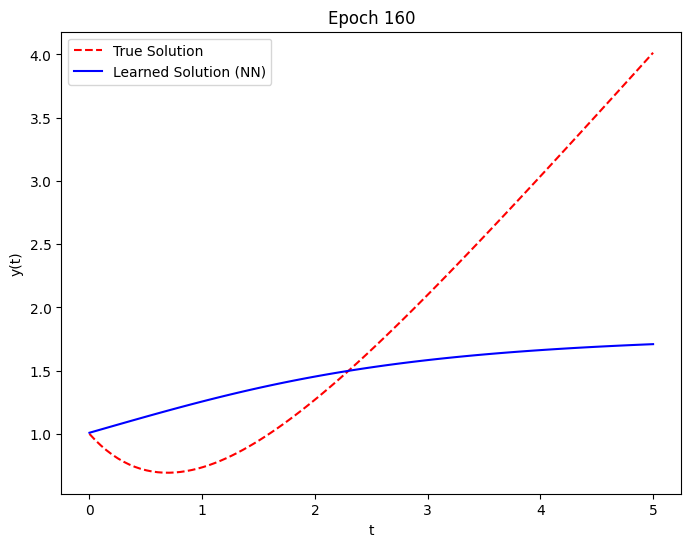

Epoch 170, Test Loss: 0.9245572686195374


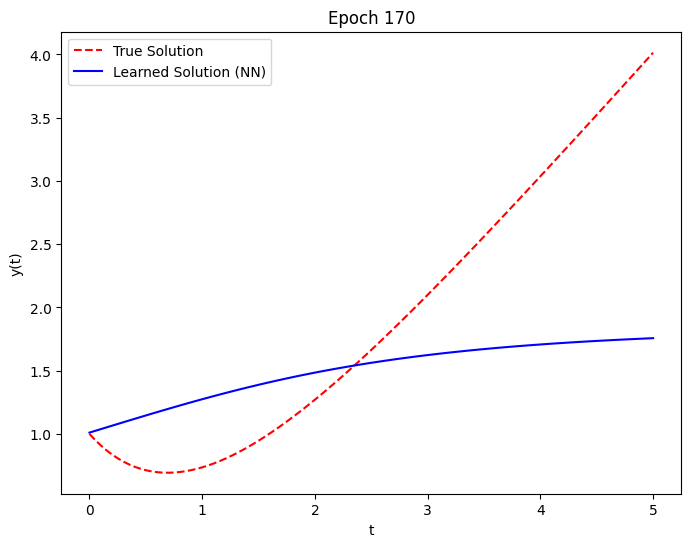

Epoch 180, Test Loss: 0.883365273475647


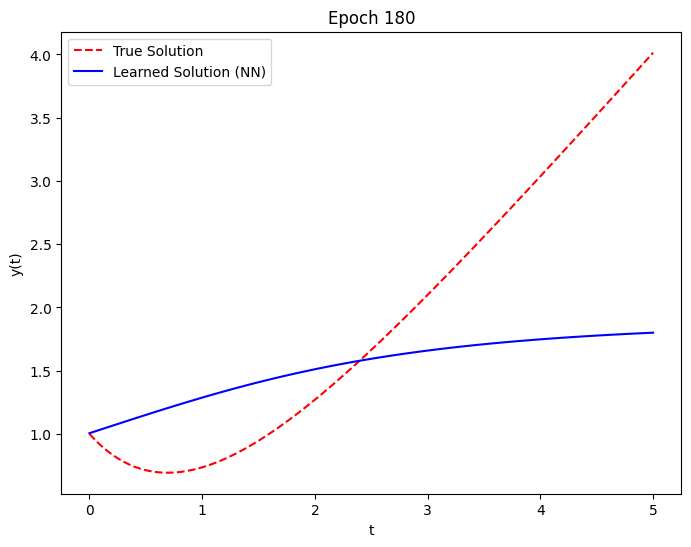

Epoch 190, Test Loss: 0.8386281728744507


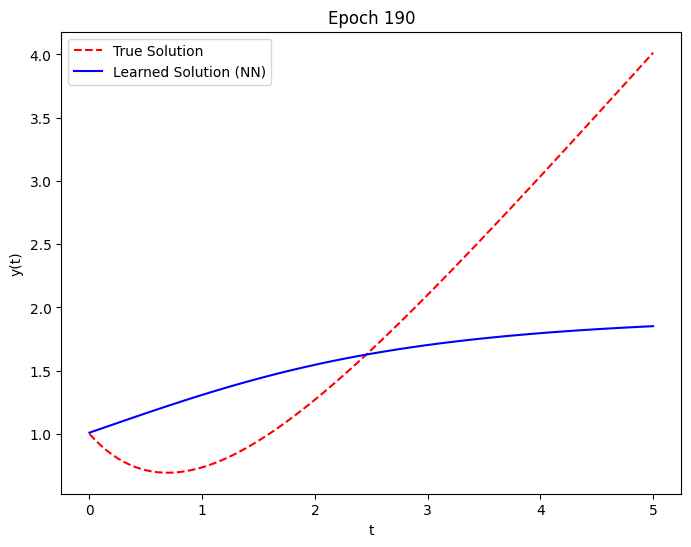

Epoch 200, Test Loss: 0.7963373064994812


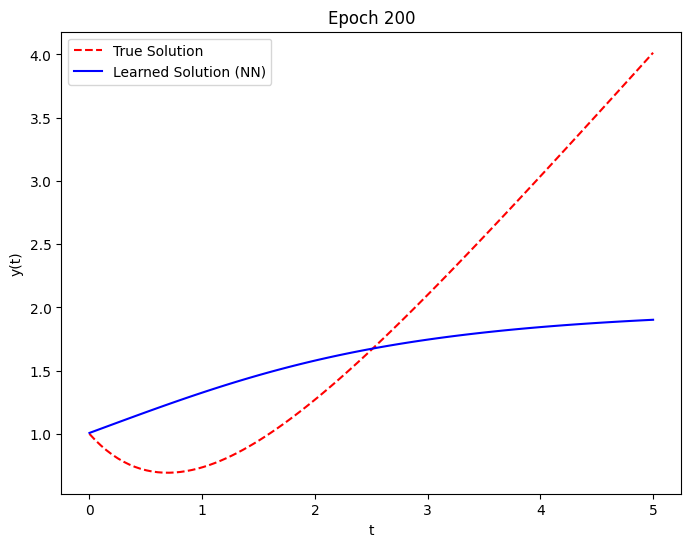

Epoch 210, Test Loss: 0.7615806460380554


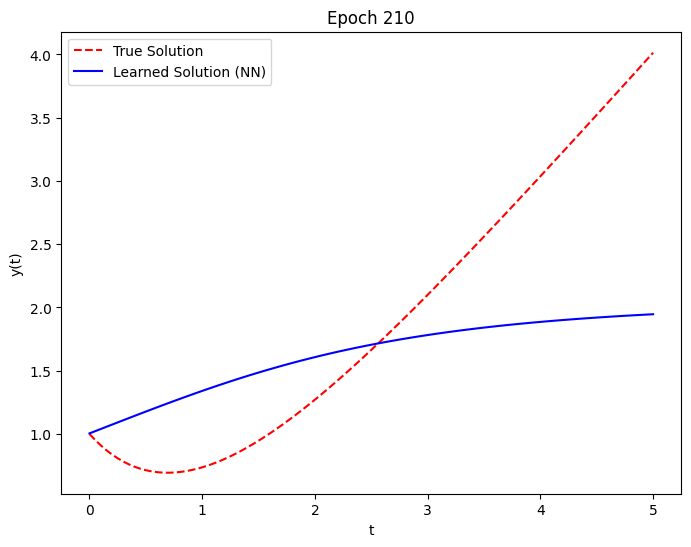

Epoch 220, Test Loss: 0.7311943173408508


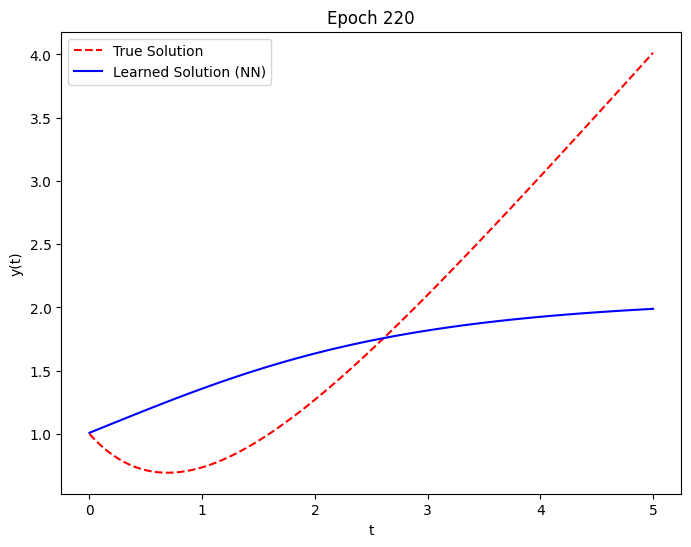

Epoch 230, Test Loss: 0.7041646838188171


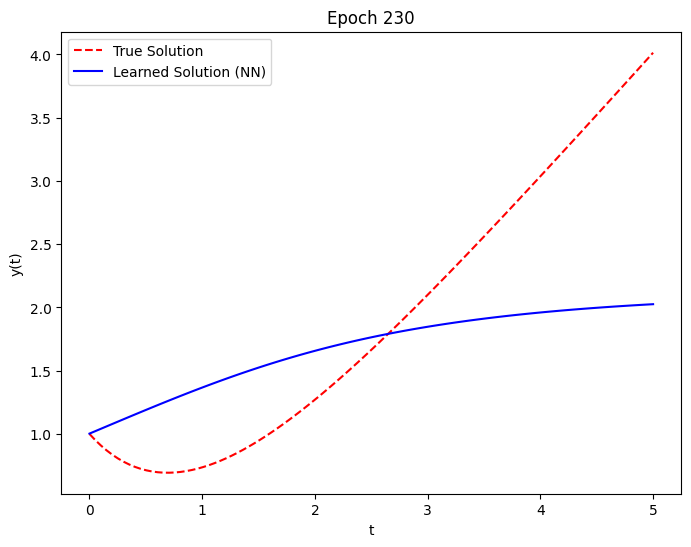

Epoch 240, Test Loss: 0.6741651892662048


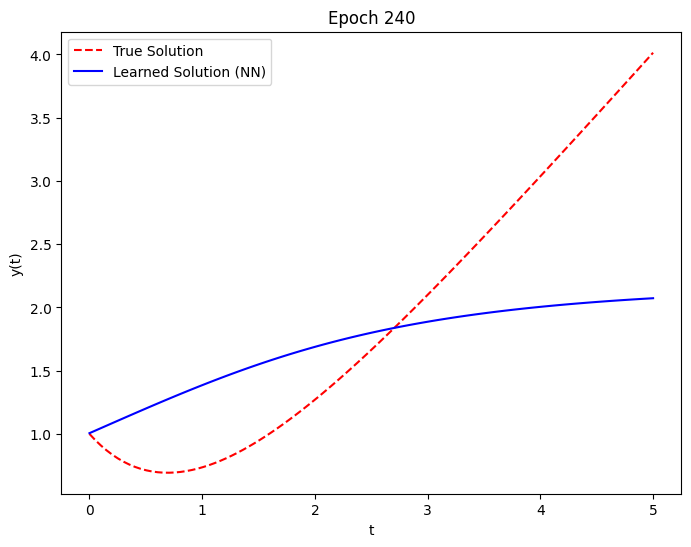

Epoch 250, Test Loss: 0.6489840149879456


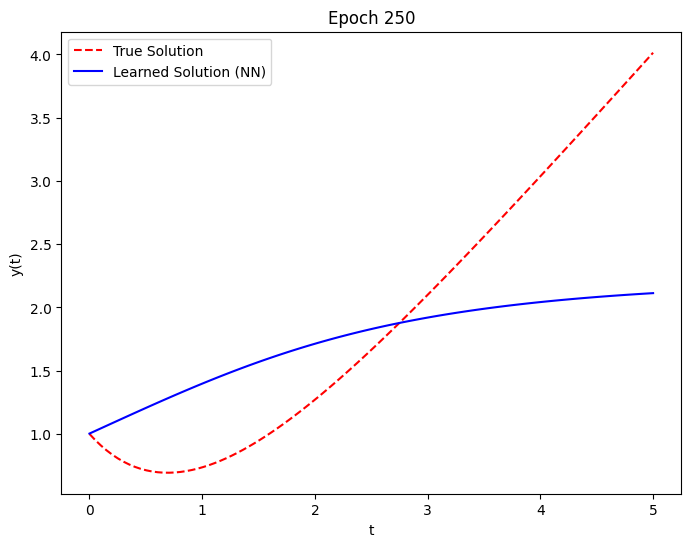

Epoch 260, Test Loss: 0.6272457838058472


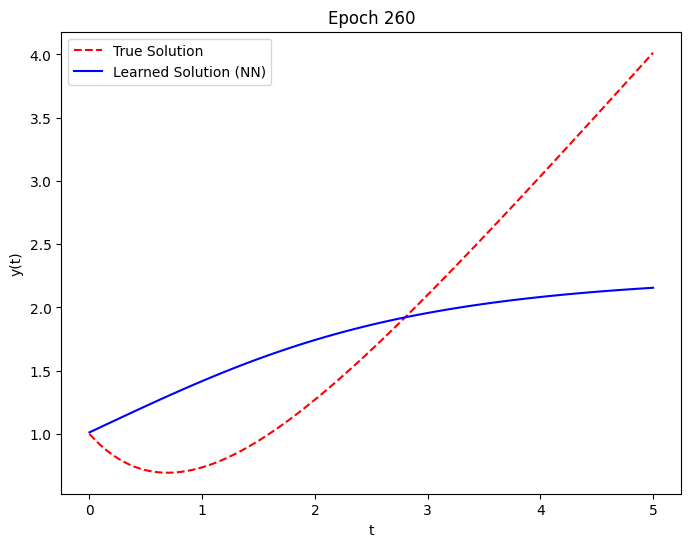

Epoch 270, Test Loss: 0.6098957061767578


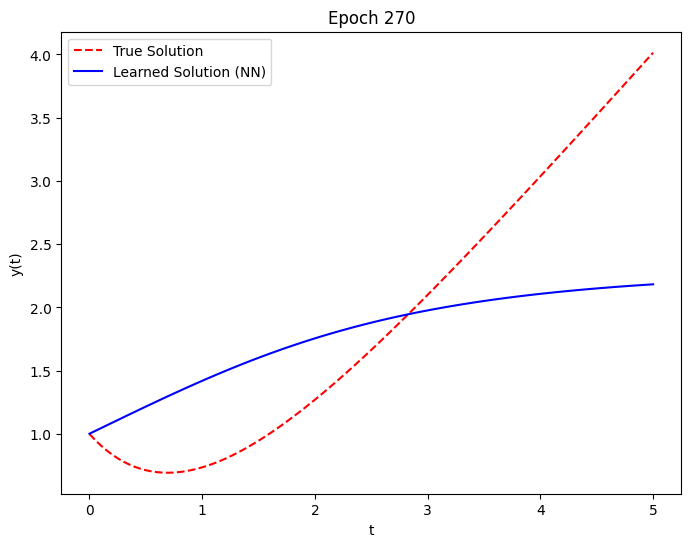

Epoch 280, Test Loss: 0.5907009243965149


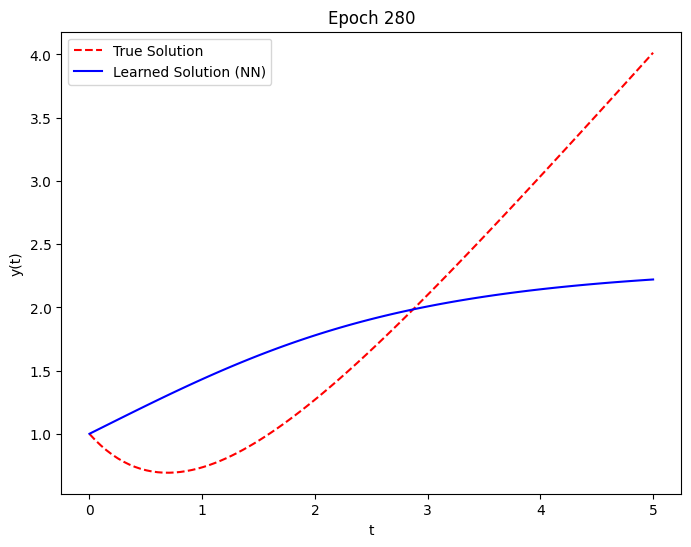

Epoch 290, Test Loss: 0.5733248591423035


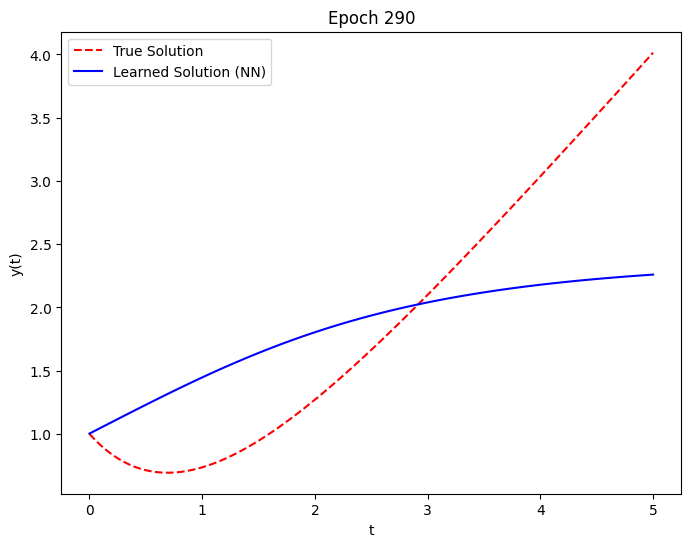

Epoch 300, Test Loss: 0.5579878091812134


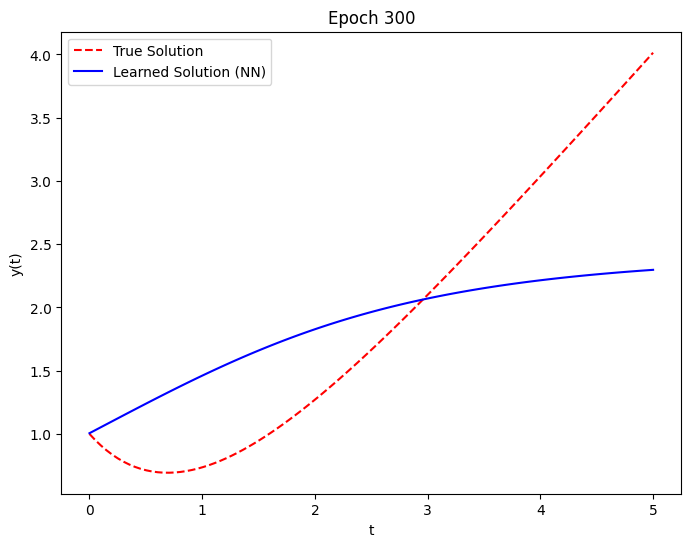

Epoch 310, Test Loss: 0.5460714101791382


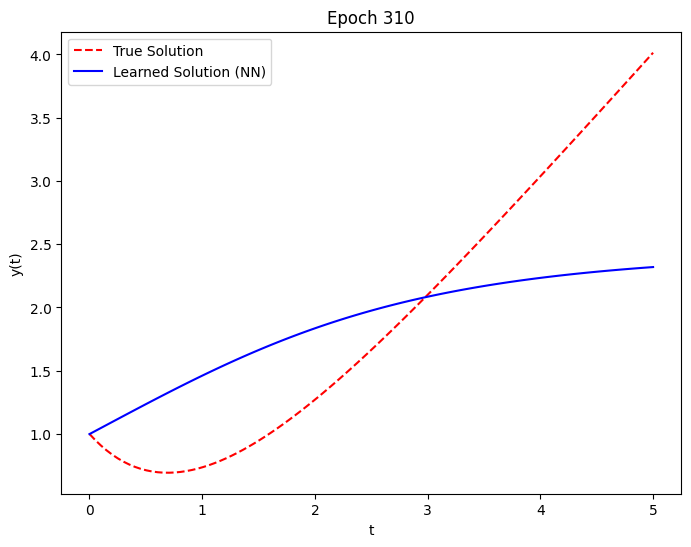

Epoch 320, Test Loss: 0.5361447930335999


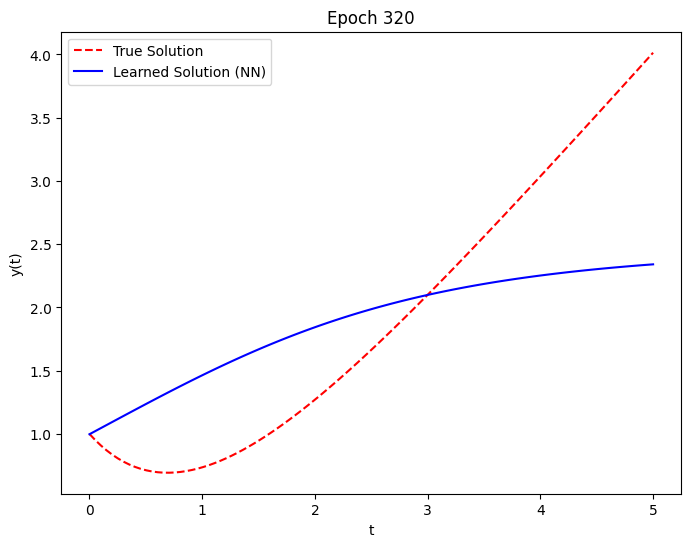

Epoch 330, Test Loss: 0.5247836112976074


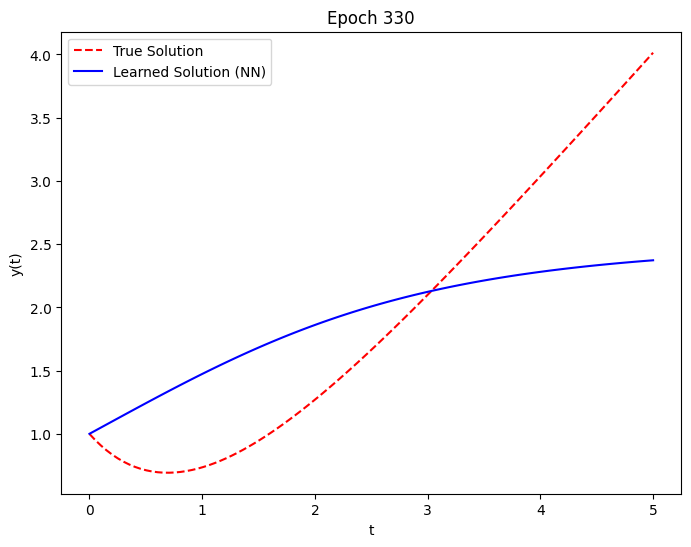

Epoch 340, Test Loss: 0.5145347118377686


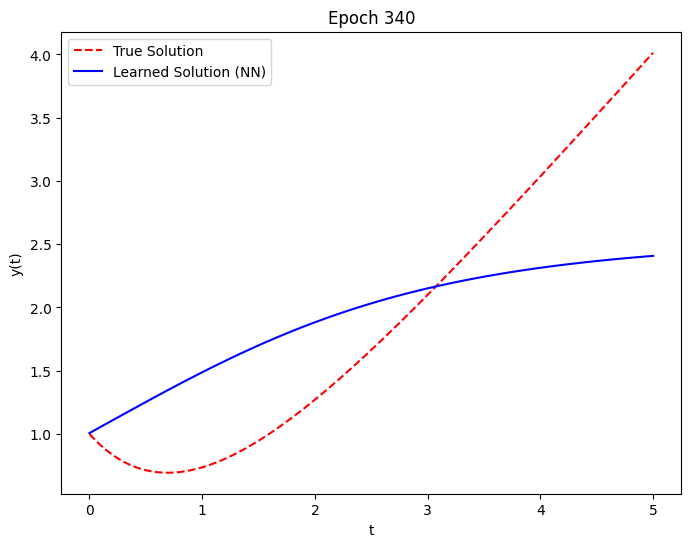

Epoch 350, Test Loss: 0.5031059384346008


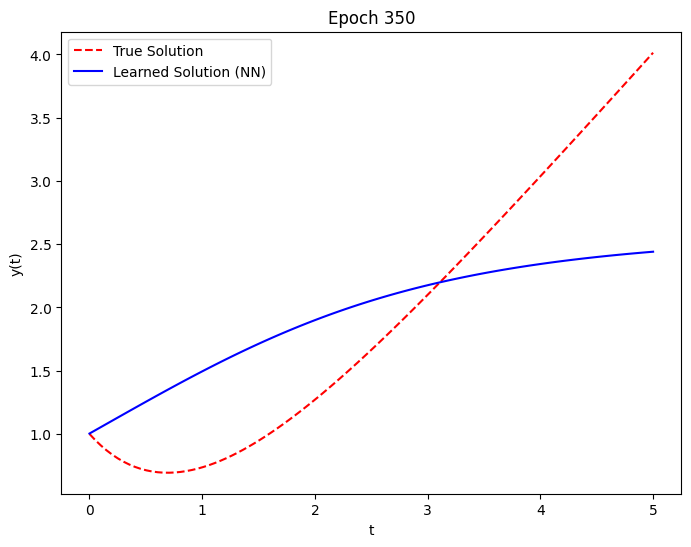

Epoch 360, Test Loss: 0.4923812448978424


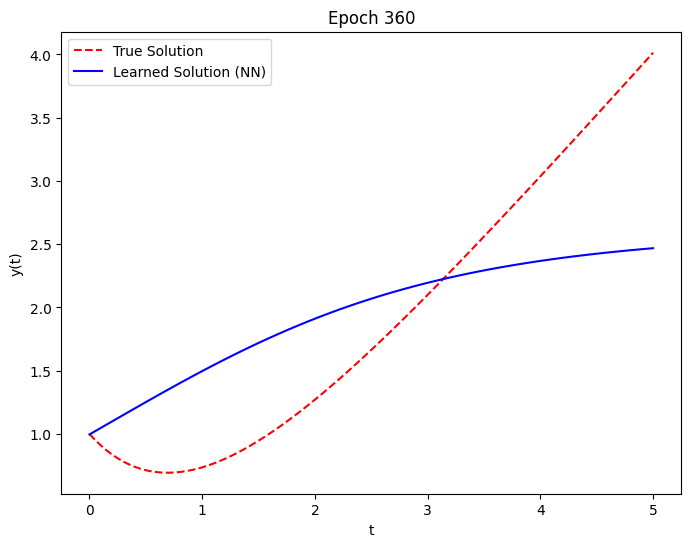

Epoch 370, Test Loss: 0.4848015606403351


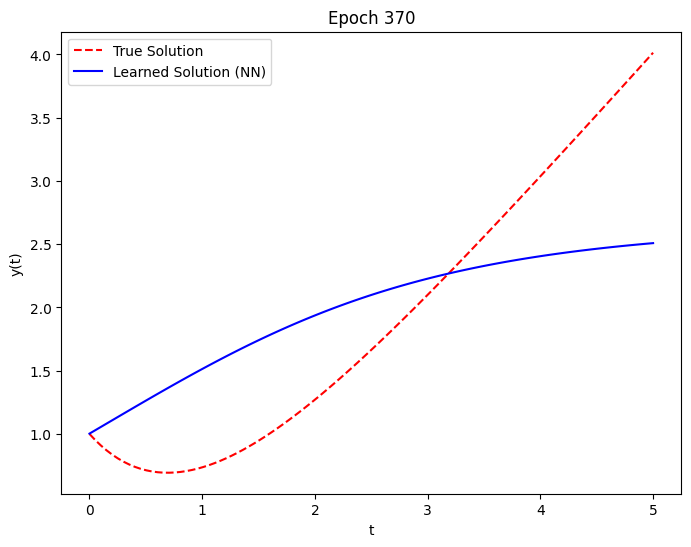

Epoch 380, Test Loss: 0.4773001968860626


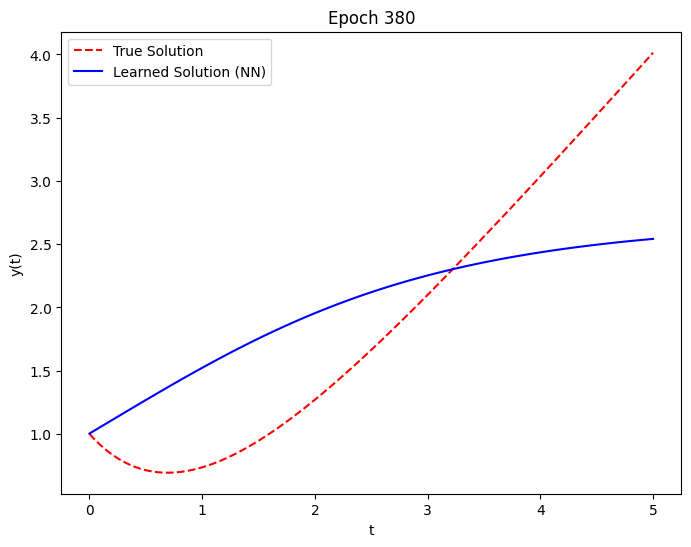

Epoch 390, Test Loss: 0.4705038368701935


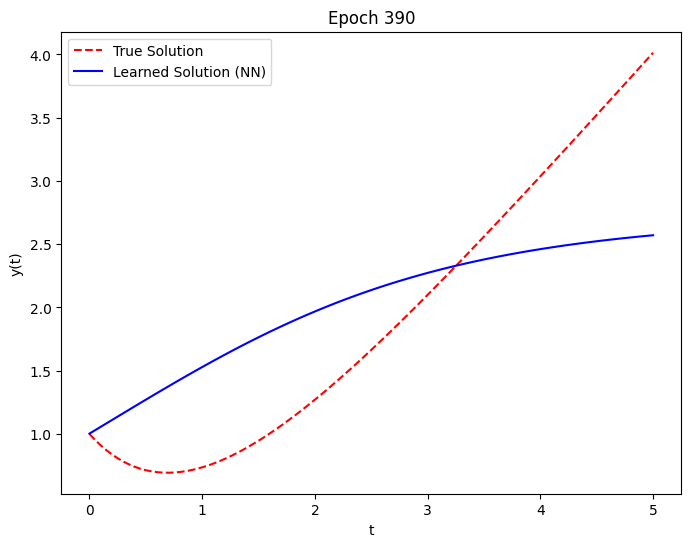

Epoch 400, Test Loss: 0.466206431388855


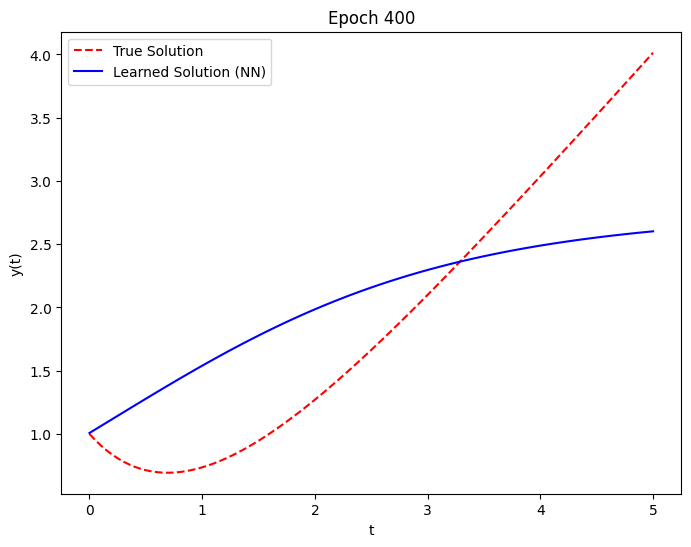

Epoch 410, Test Loss: 0.4583778381347656


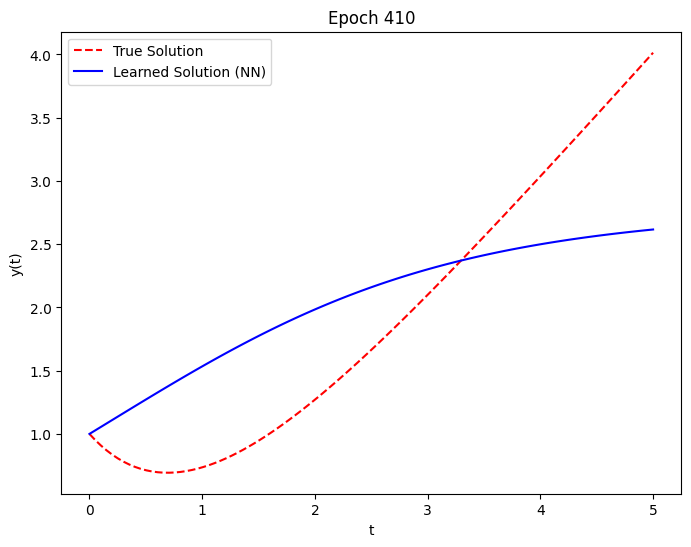

Epoch 420, Test Loss: 0.45067572593688965


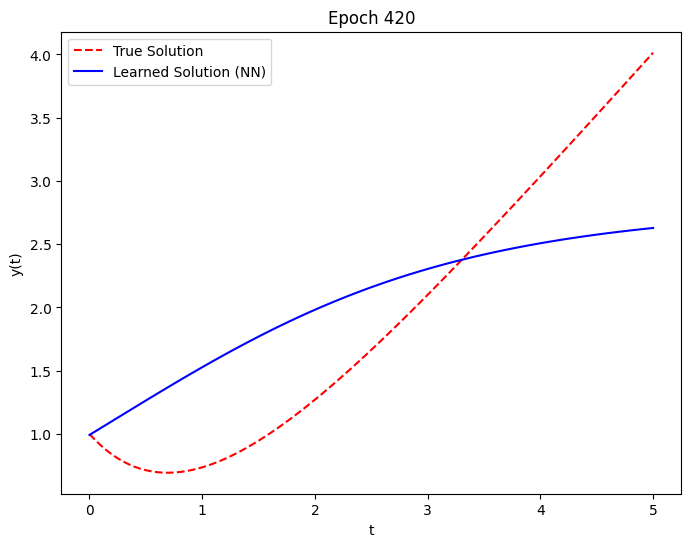

Epoch 430, Test Loss: 0.44853827357292175


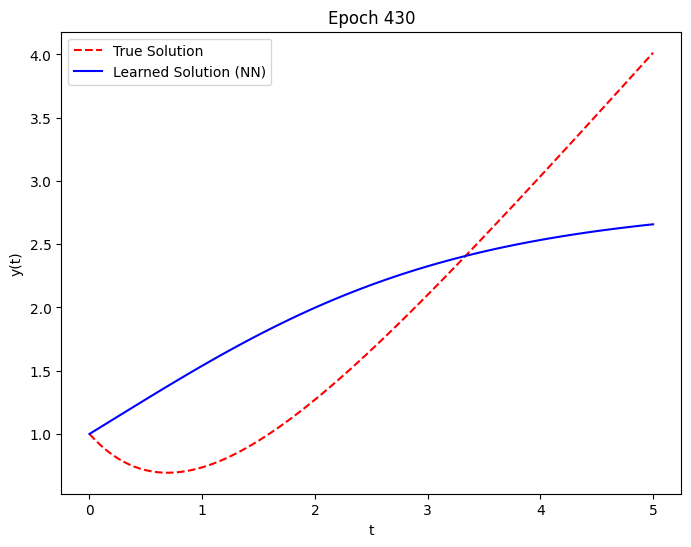

Epoch 440, Test Loss: 0.44492125511169434


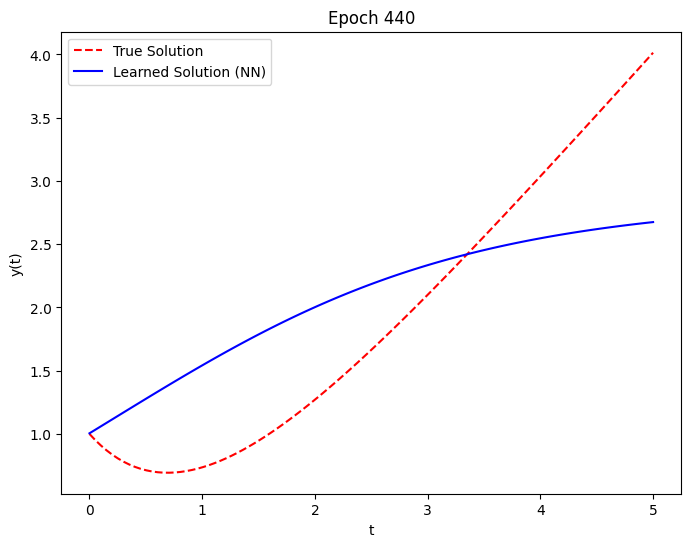

Epoch 450, Test Loss: 0.43958795070648193


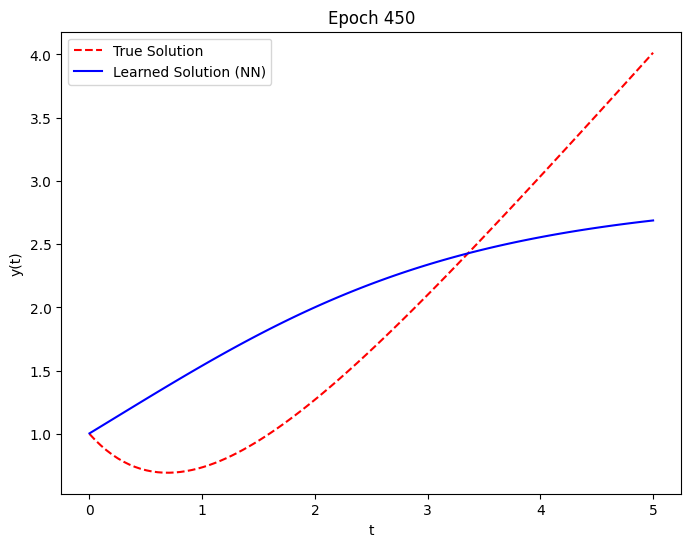

Epoch 460, Test Loss: 0.4342920780181885


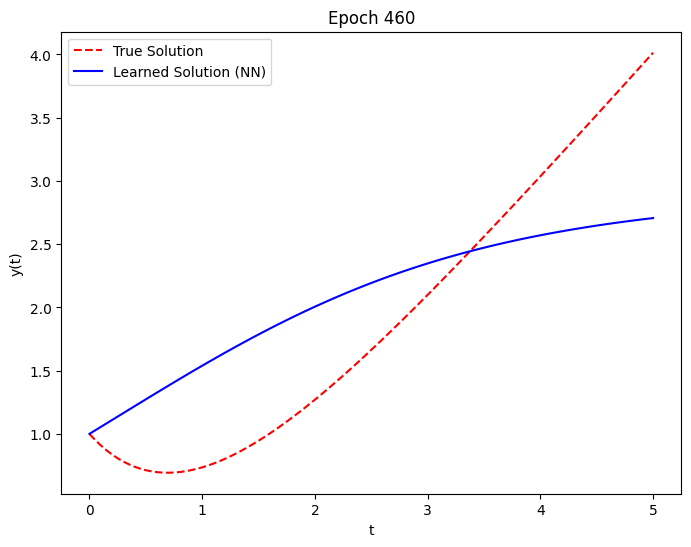

Epoch 470, Test Loss: 0.42978569865226746


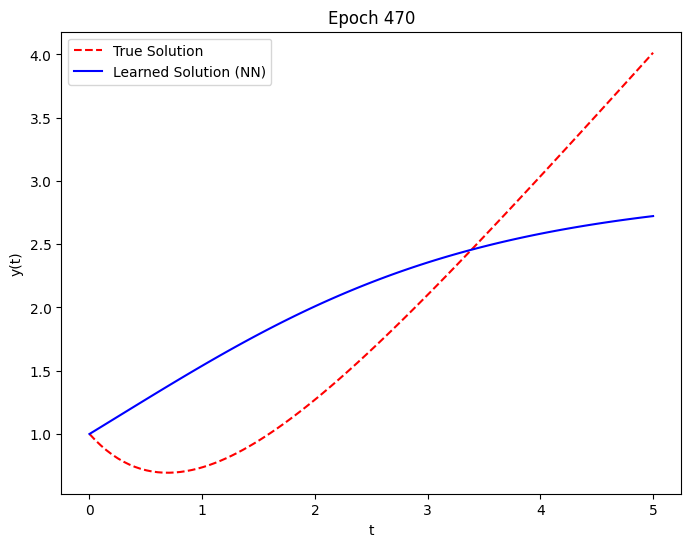

Epoch 480, Test Loss: 0.42573538422584534


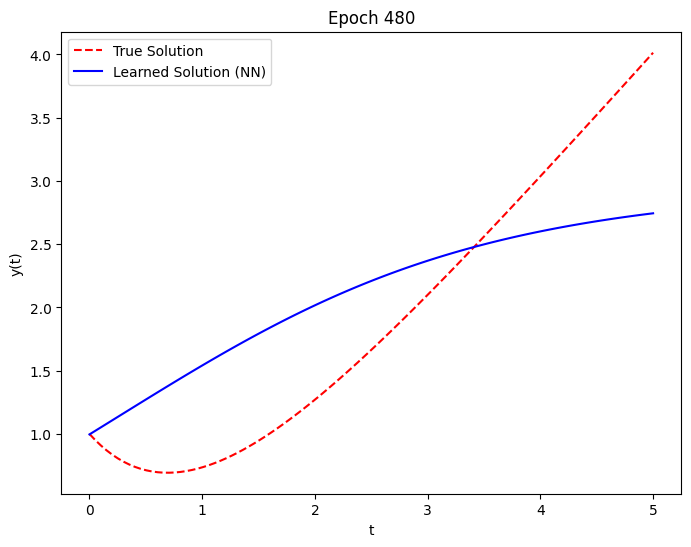

Epoch 490, Test Loss: 0.42105209827423096


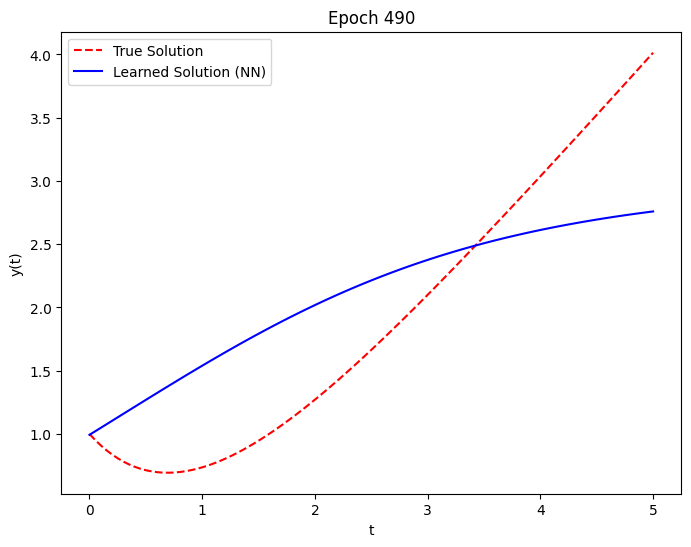

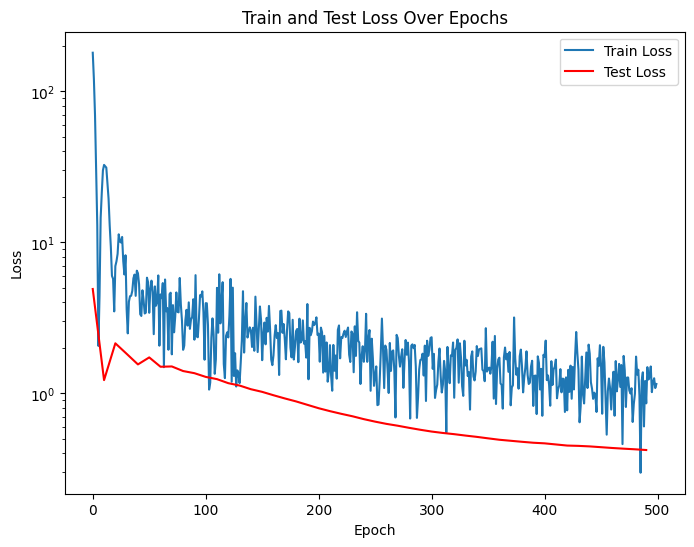

In [ ]:
# Initialize the model
set_seed(1)
model = NeuralNet()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# Run the training
num_epochs, train_losses, test_losses = train_ode_solver_weight(model, optimizer, weight_IC=100)
plot_losses(num_epochs, train_losses, test_losses)

## Exercise 1

Modify the code to put the main (remaining) hyperparameters as inputs of `train_ode_solver`.

## Exercise 2

Try with:
- other values for the hyperparameters
- other optimizers
- other ODEs

# Architecture satisfying the IC

In [ ]:
class CustomNeuralNet(nn.Module):
    def __init__(self, y_0, T):
        super(CustomNeuralNet, self).__init__()
        self.y_0 = y_0
        self.T = T

        # Base neural network architecture (same as NeuralNet)
        # TODO

    def forward(self, t):
        # Neural network output NN_theta(t)
        # TODO

        # Enforced architecture: y_0 + (t / T) * NN_theta(t)
        return # TODO

Epoch 0, Test Loss: 2.0010263919830322


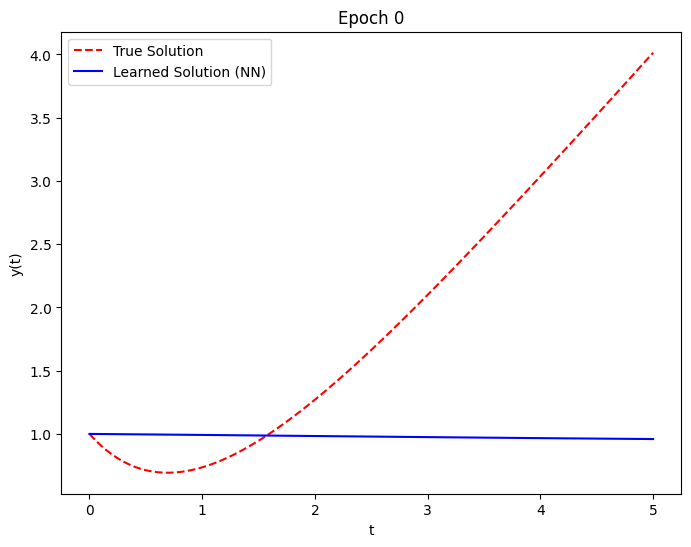

Epoch 10, Test Loss: 0.24921724200248718


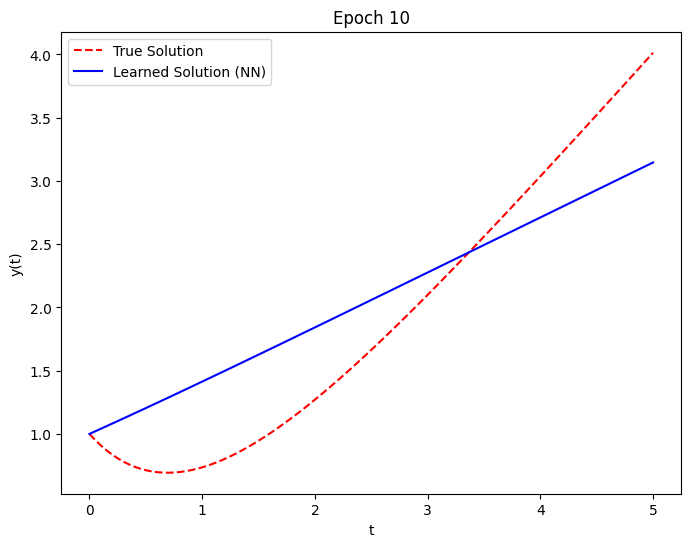

Epoch 20, Test Loss: 0.46673721075057983


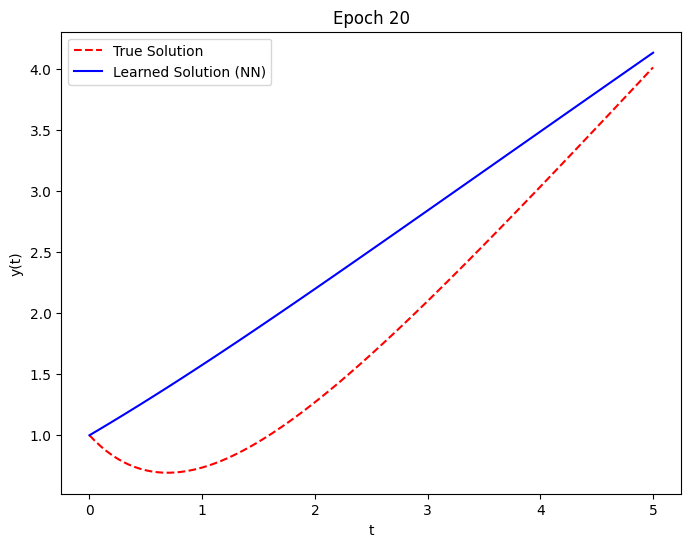

Epoch 30, Test Loss: 0.33480095863342285


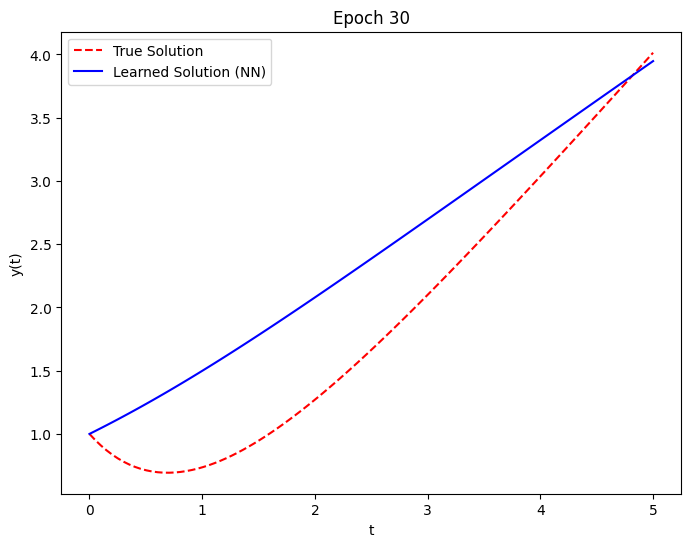

Epoch 40, Test Loss: 0.18747302889823914


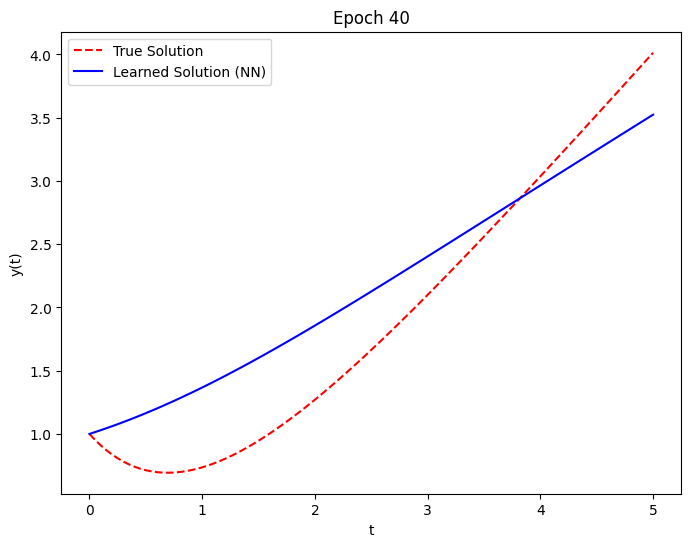

Epoch 50, Test Loss: 0.16384615004062653


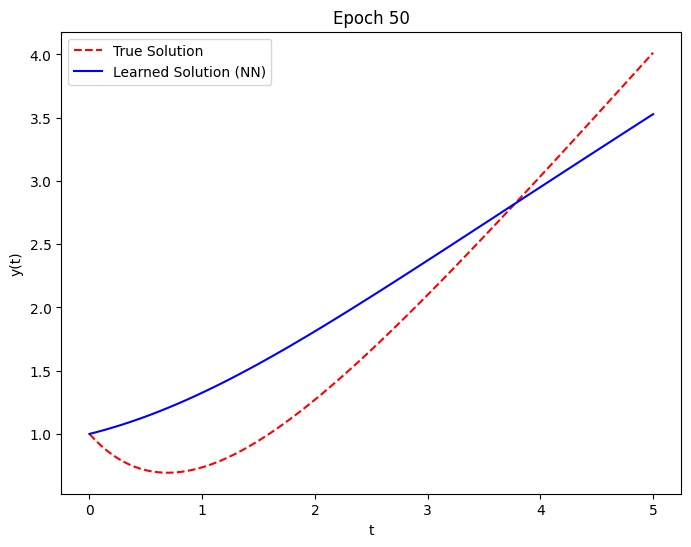

Epoch 60, Test Loss: 0.16853946447372437


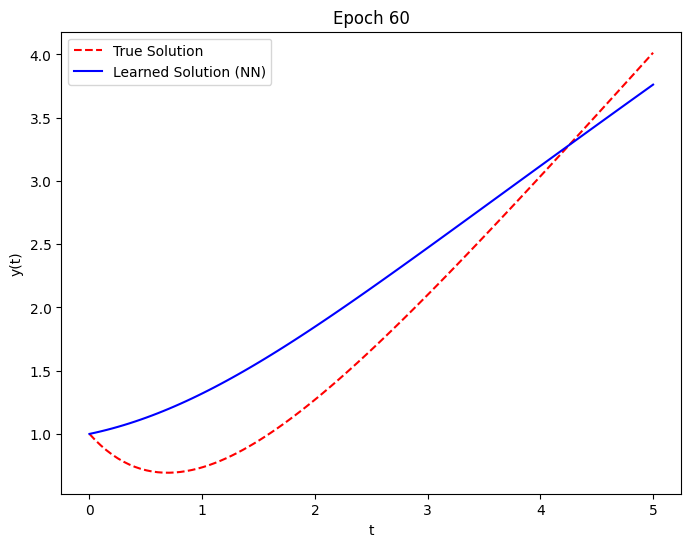

Epoch 70, Test Loss: 0.13193146884441376


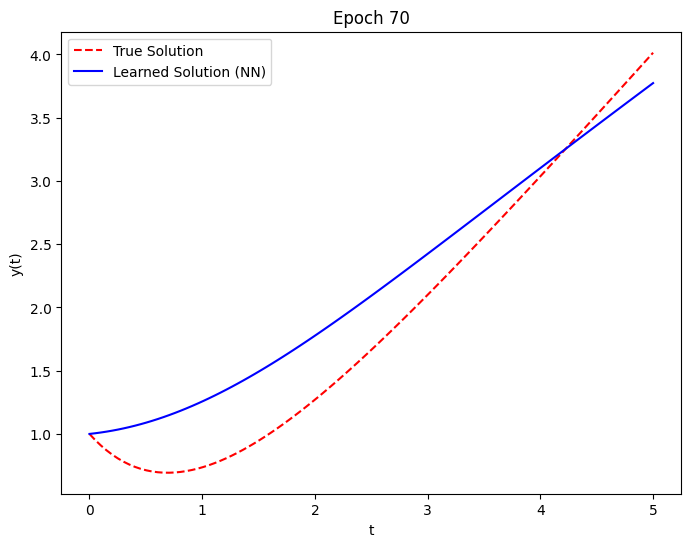

Epoch 80, Test Loss: 0.0858609676361084


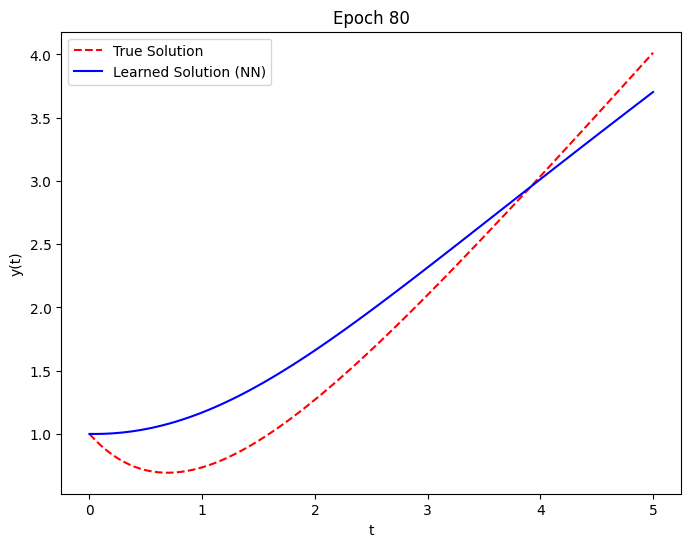

Epoch 90, Test Loss: 0.056787777692079544


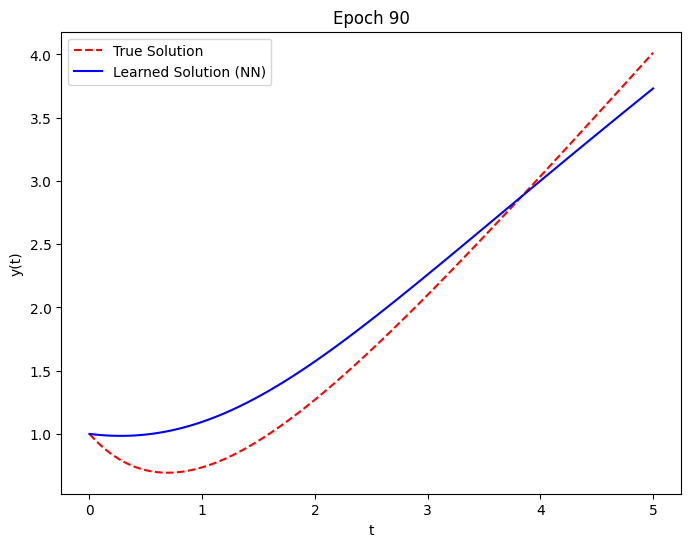

Epoch 100, Test Loss: 0.0448872335255146


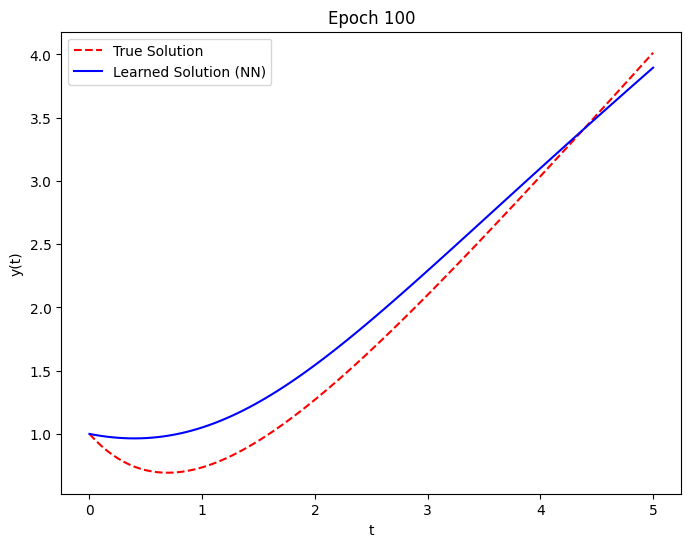

Epoch 110, Test Loss: 0.020140571519732475


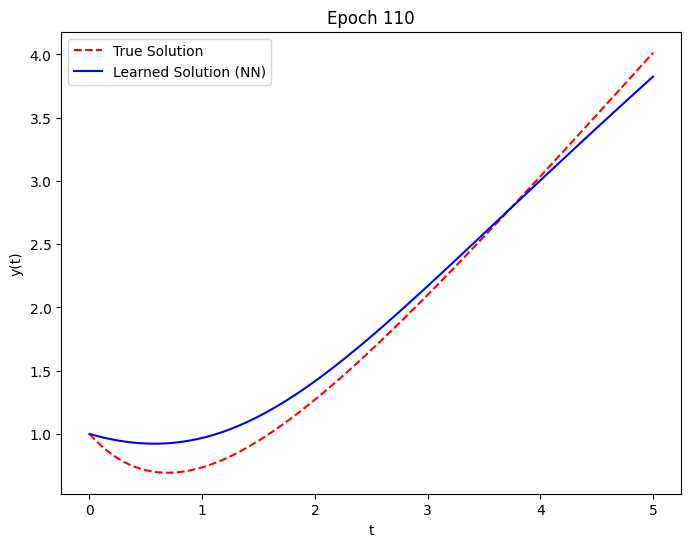

Epoch 120, Test Loss: 0.014339269138872623


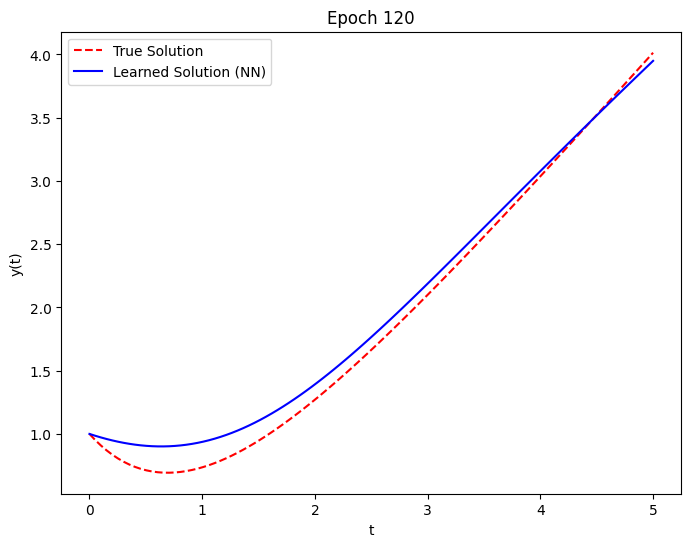

Epoch 130, Test Loss: 0.007319365628063679


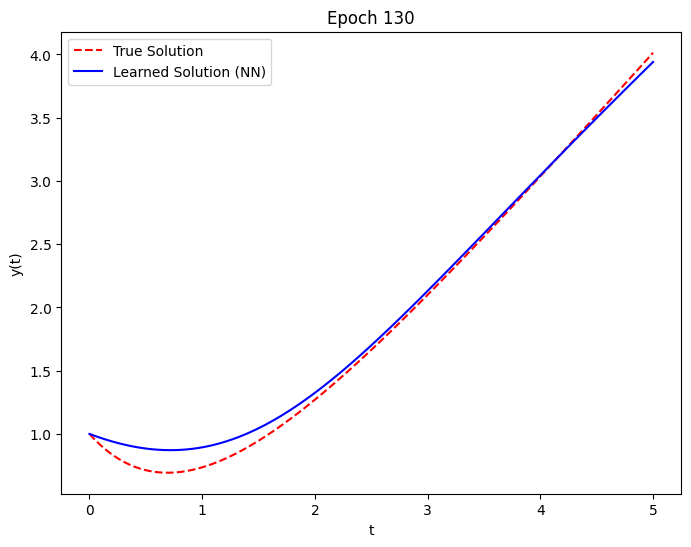

Epoch 140, Test Loss: 0.005290198139846325


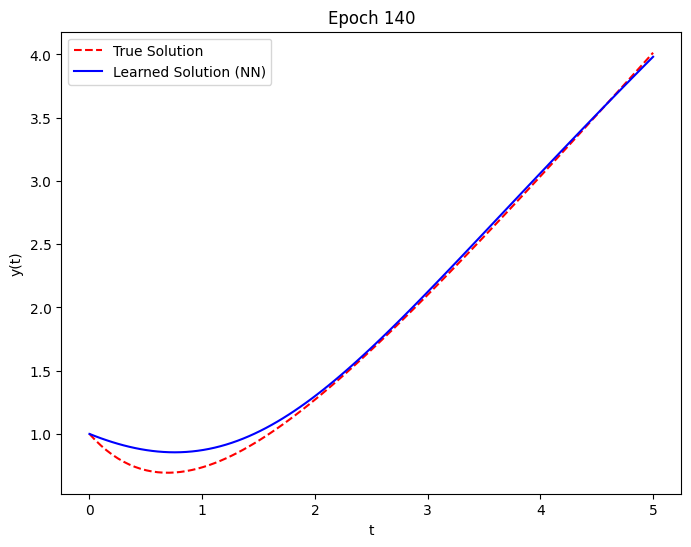

Epoch 150, Test Loss: 0.0046685864217579365


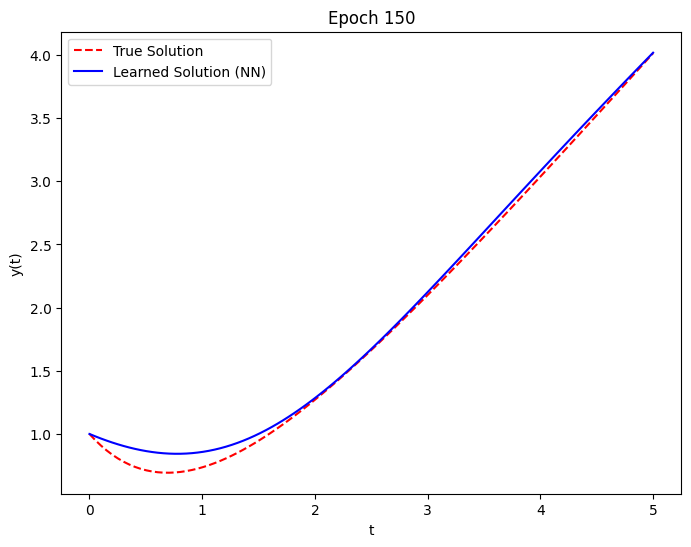

Epoch 160, Test Loss: 0.0034196802880614996


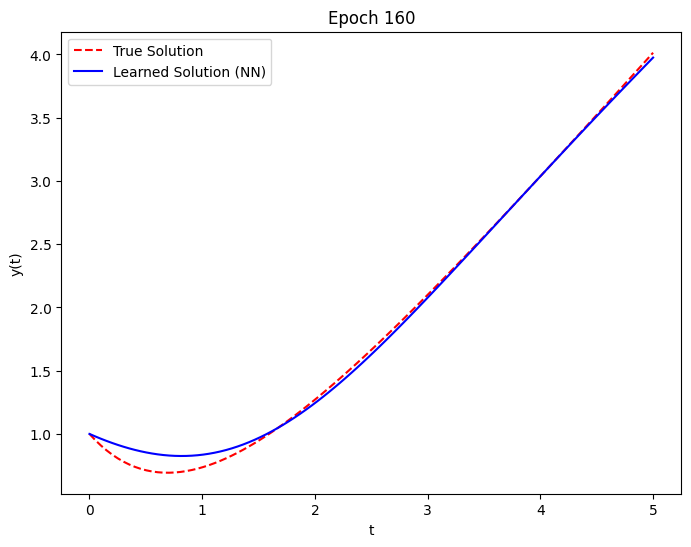

Epoch 170, Test Loss: 0.003316344693303108


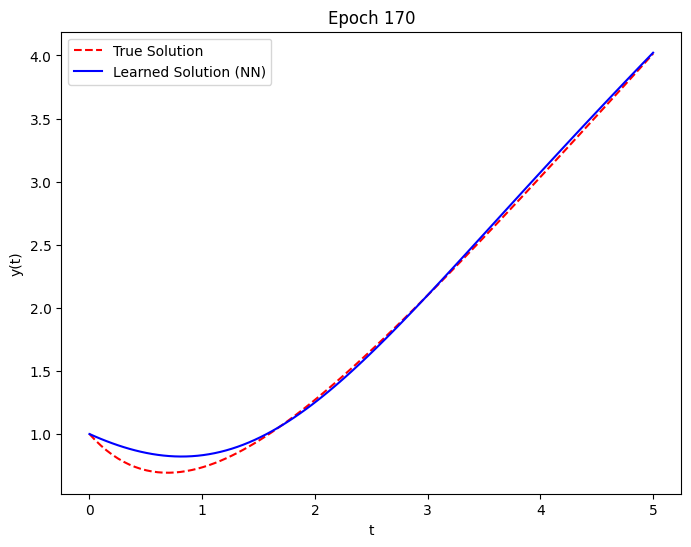

Epoch 180, Test Loss: 0.002883325796574354


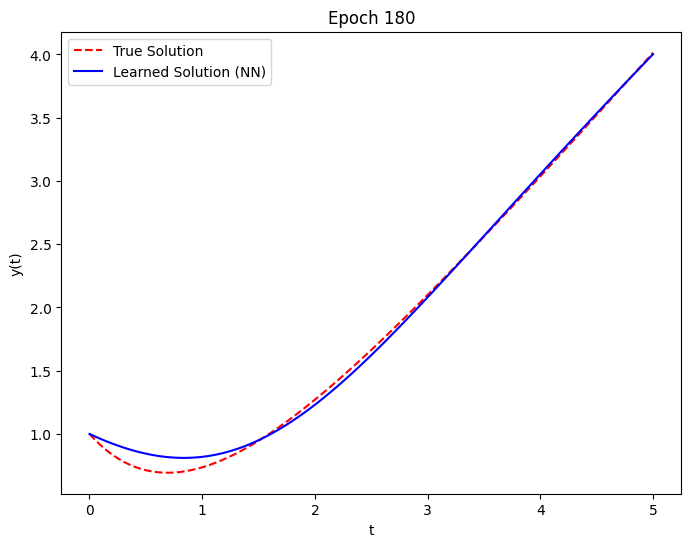

Epoch 190, Test Loss: 0.0027579045854508877


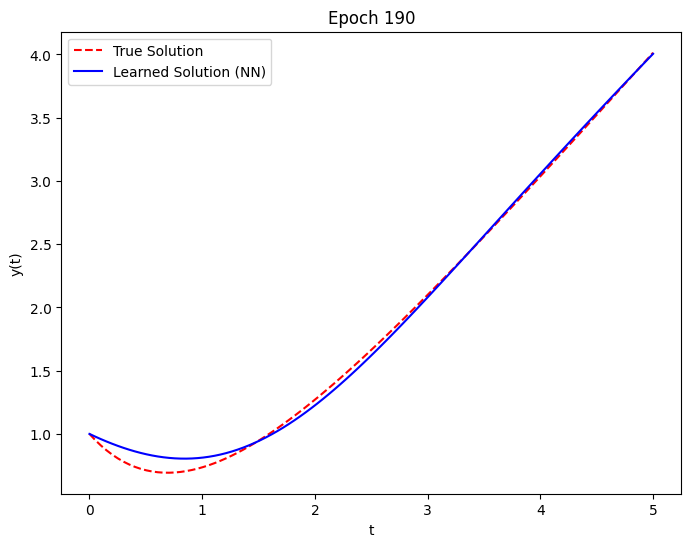

Epoch 200, Test Loss: 0.003172709373757243


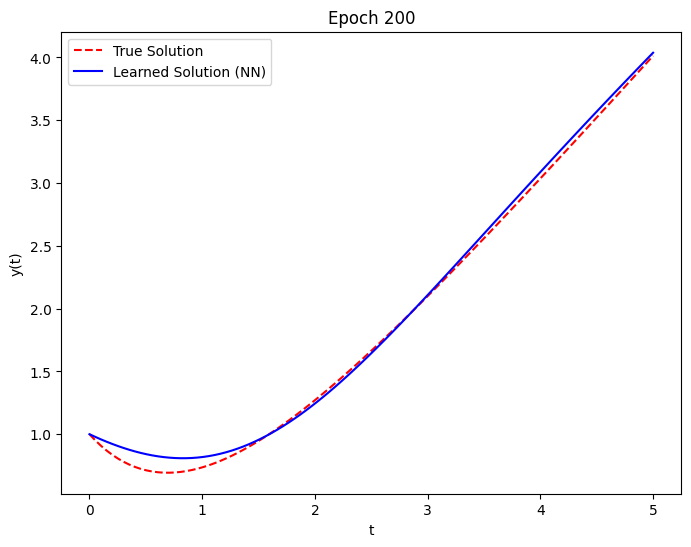

Epoch 210, Test Loss: 0.0025928118266165257


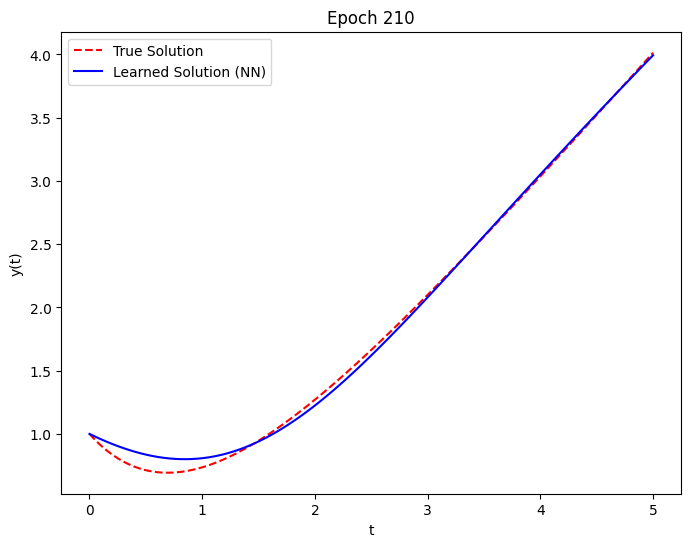

Epoch 220, Test Loss: 0.002612197771668434


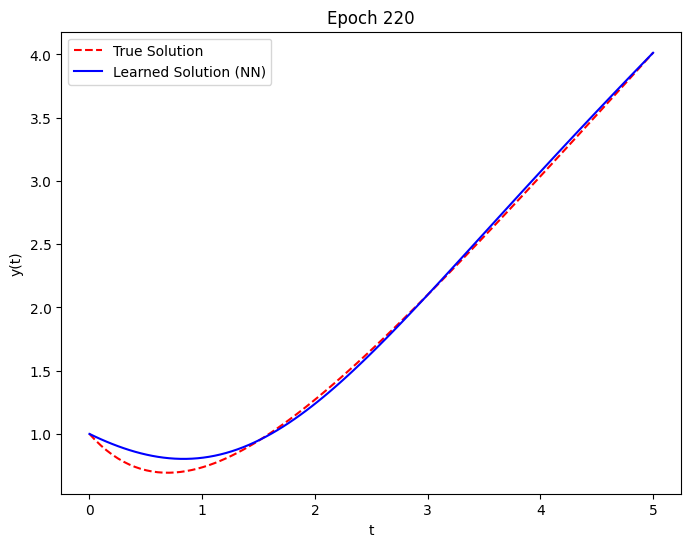

Epoch 230, Test Loss: 0.0024066022597253323


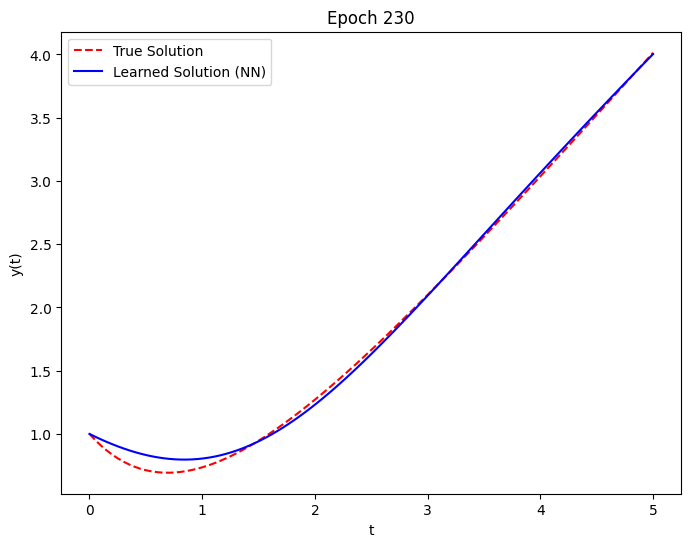

Epoch 240, Test Loss: 0.002779447939246893


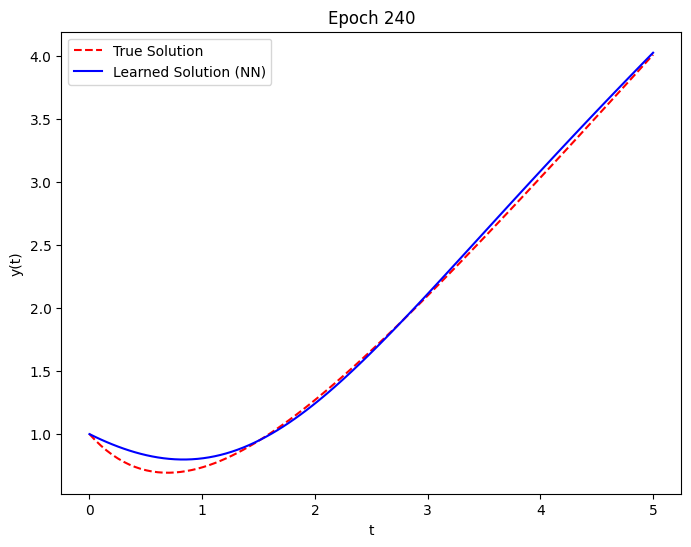

Epoch 250, Test Loss: 0.00240192748606205


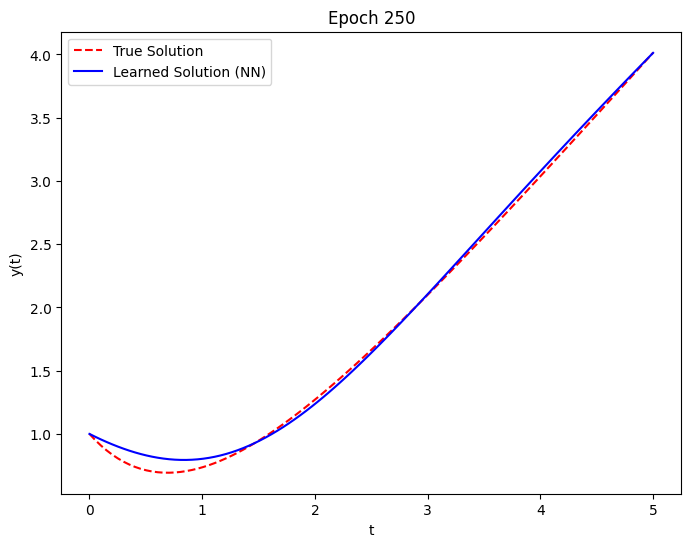

Epoch 260, Test Loss: 0.002176381181925535


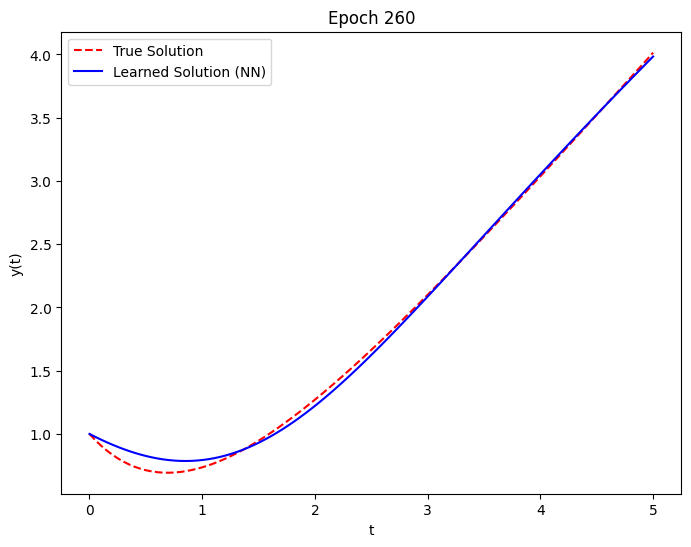

Epoch 270, Test Loss: 0.0023212581872940063


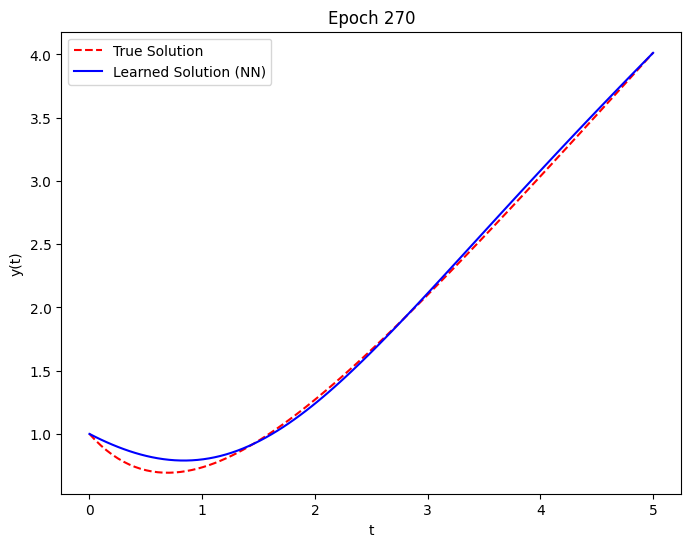

Epoch 280, Test Loss: 0.00202136836014688


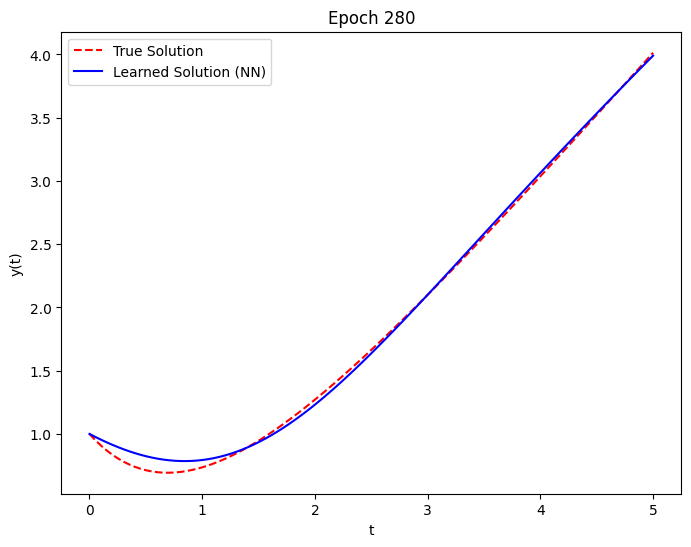

Epoch 290, Test Loss: 0.0020925551652908325


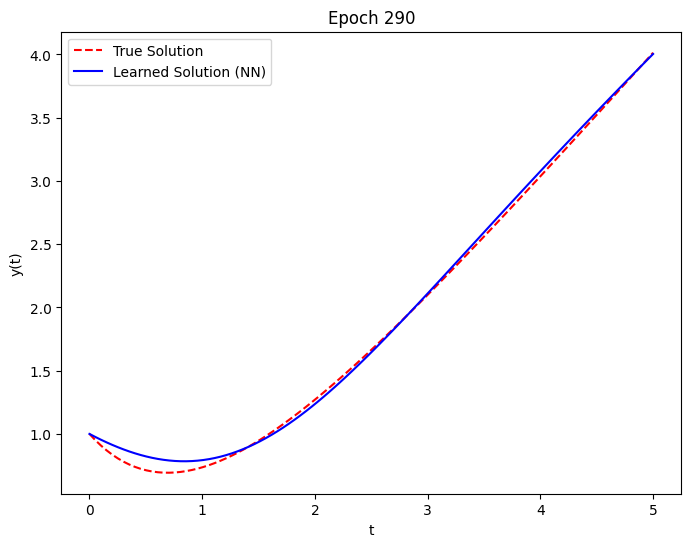

Epoch 300, Test Loss: 0.0022036812733858824


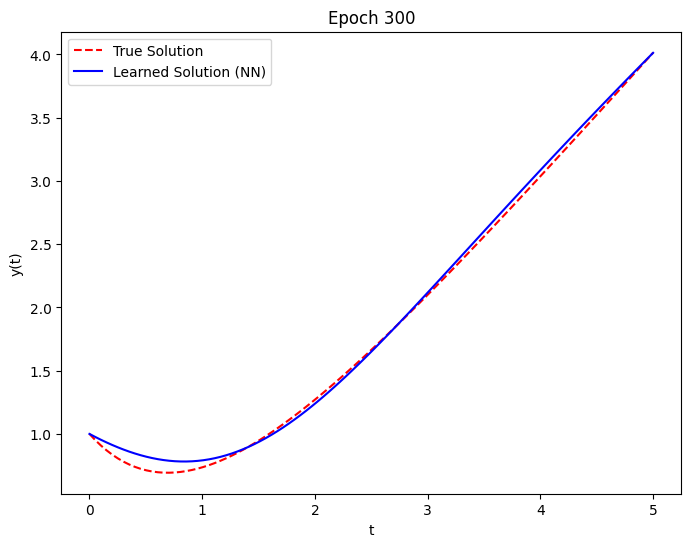

Epoch 310, Test Loss: 0.0021119029261171818


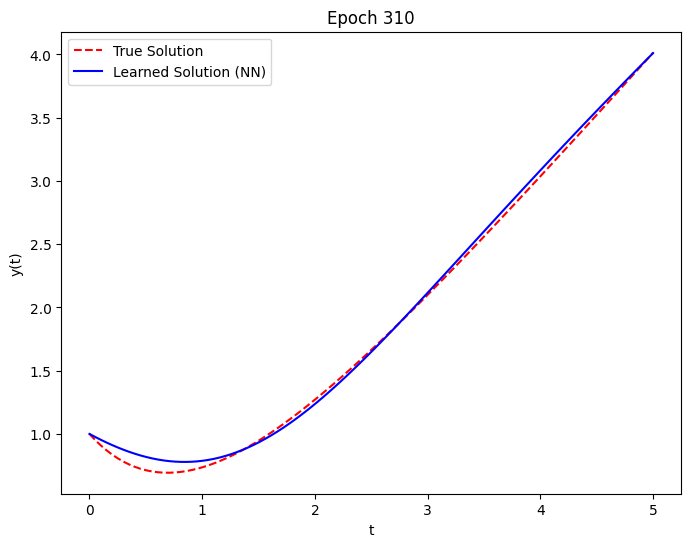

Epoch 320, Test Loss: 0.0022216441575437784


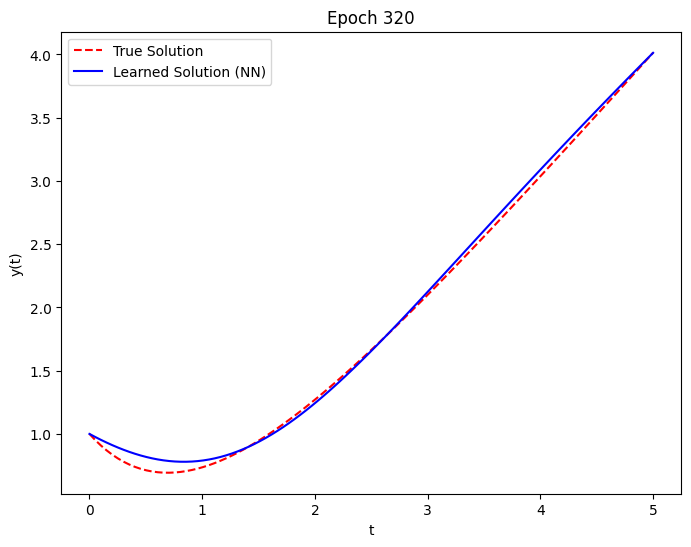

Epoch 330, Test Loss: 0.0018198390025645494


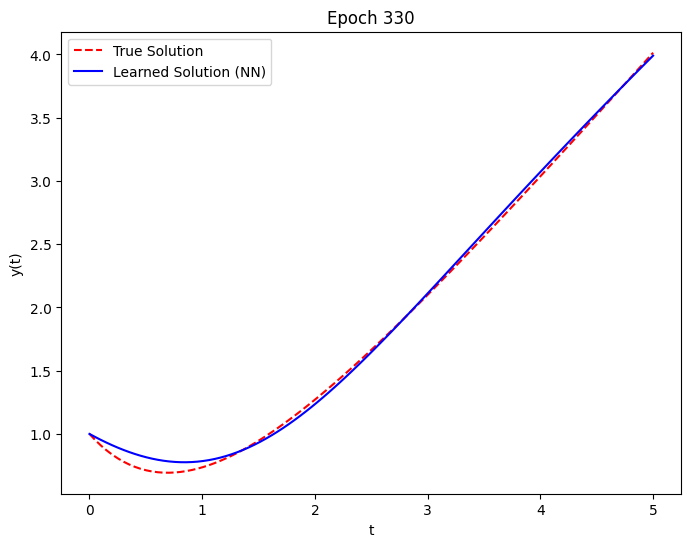

Epoch 340, Test Loss: 0.0019853832200169563


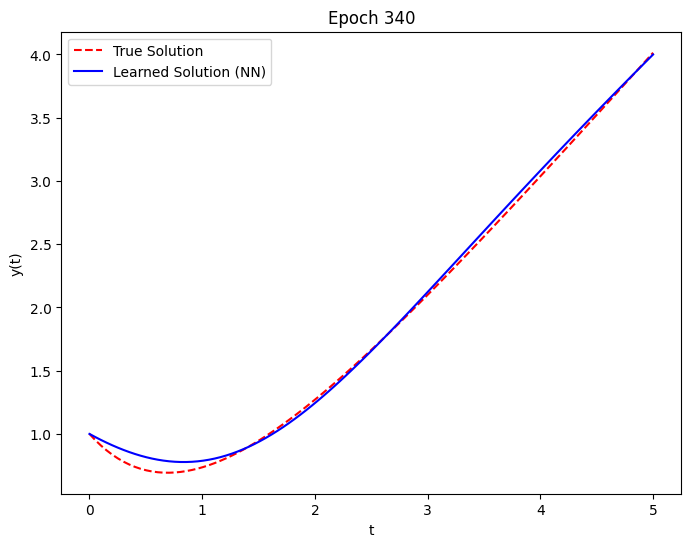

Epoch 350, Test Loss: 0.0019805992487818003


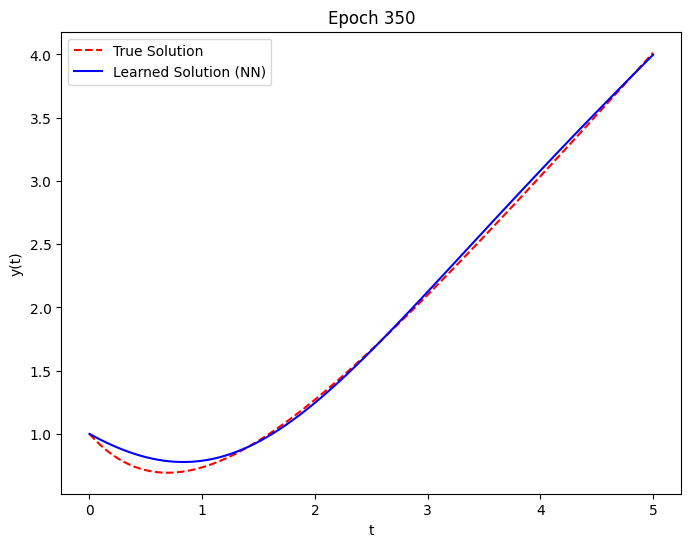

Epoch 360, Test Loss: 0.0019339598948135972


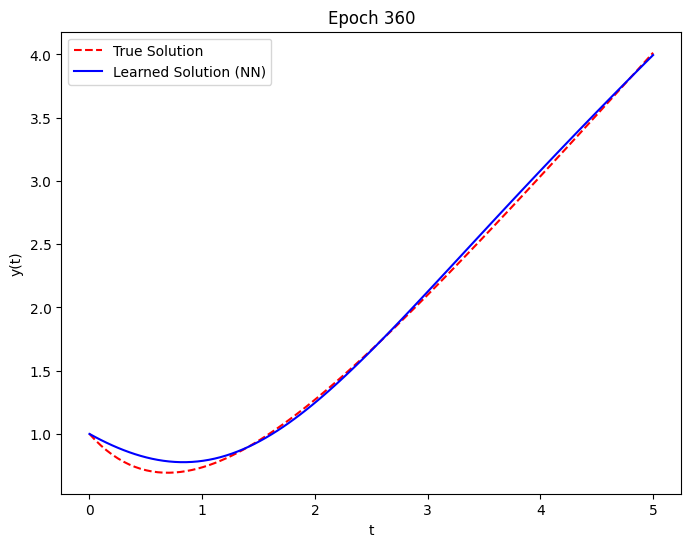

Epoch 370, Test Loss: 0.001635052845813334


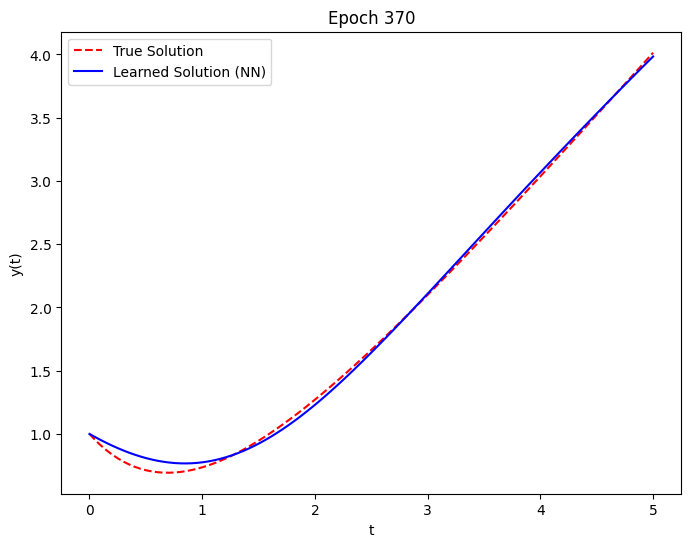

Epoch 380, Test Loss: 0.002342302119359374


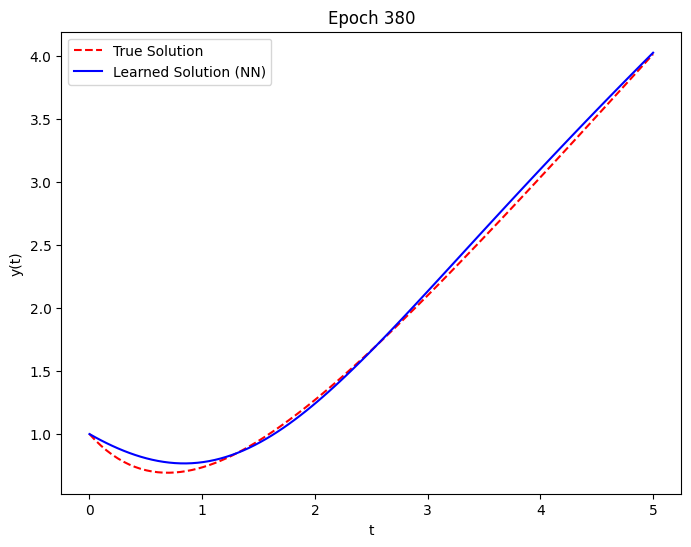

Epoch 390, Test Loss: 0.0017662629252299666


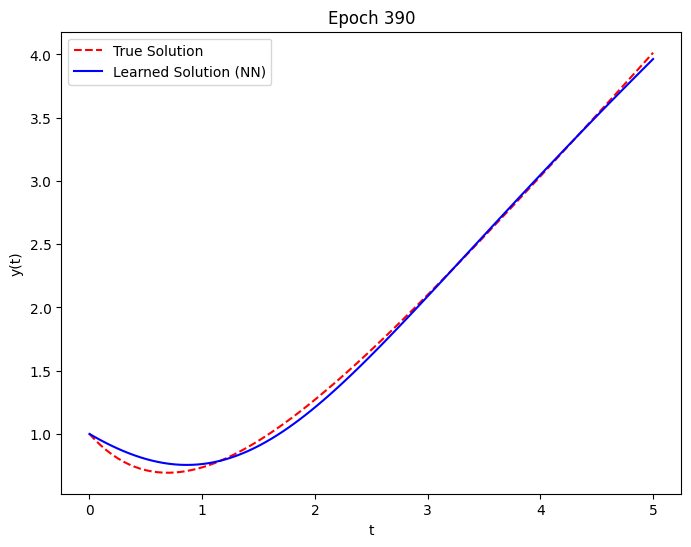

Epoch 400, Test Loss: 0.001673509948886931


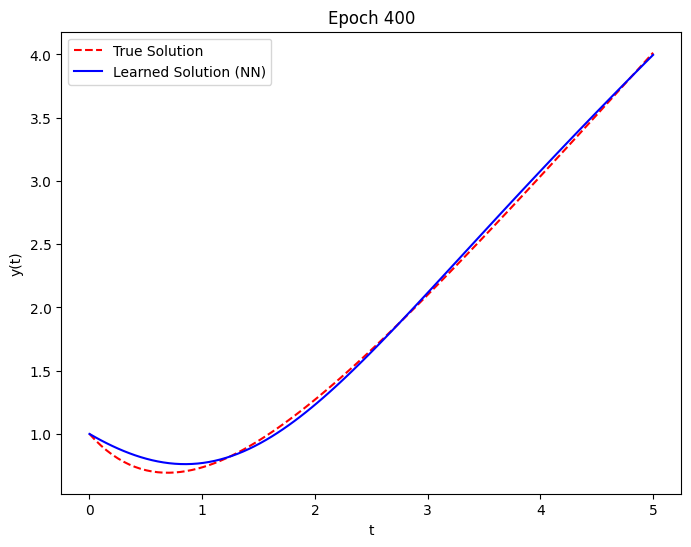

Epoch 410, Test Loss: 0.001813675626181066


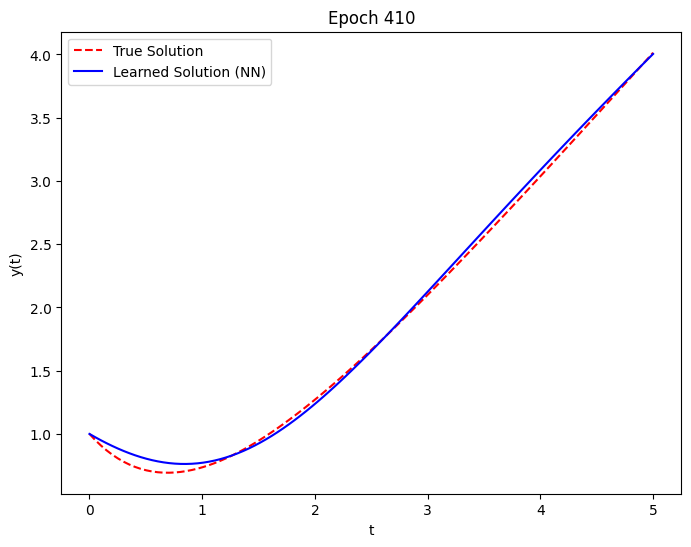

Epoch 420, Test Loss: 0.001481544808484614


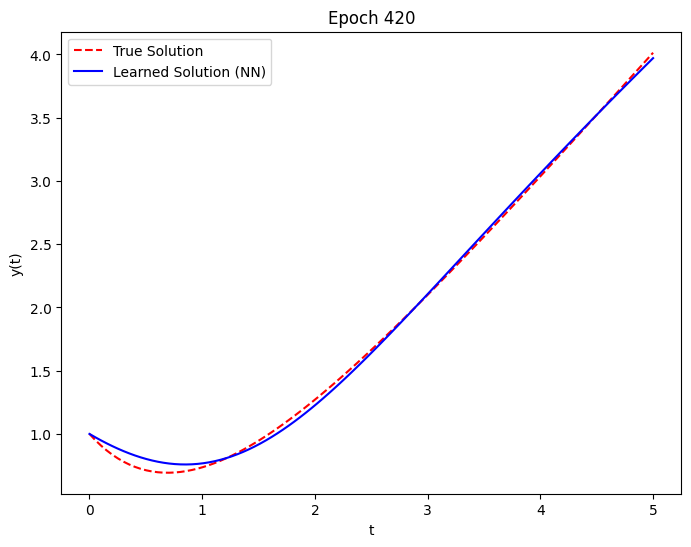

Epoch 430, Test Loss: 0.002311124699190259


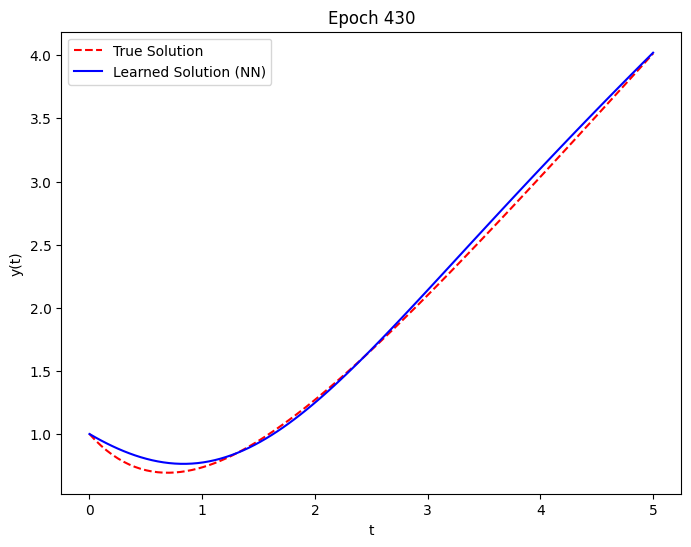

Epoch 440, Test Loss: 0.0016306318575516343


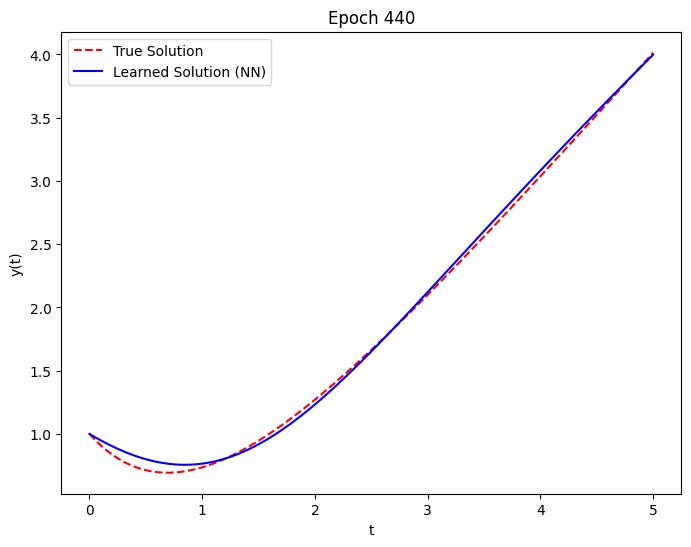

Epoch 450, Test Loss: 0.0020819175988435745


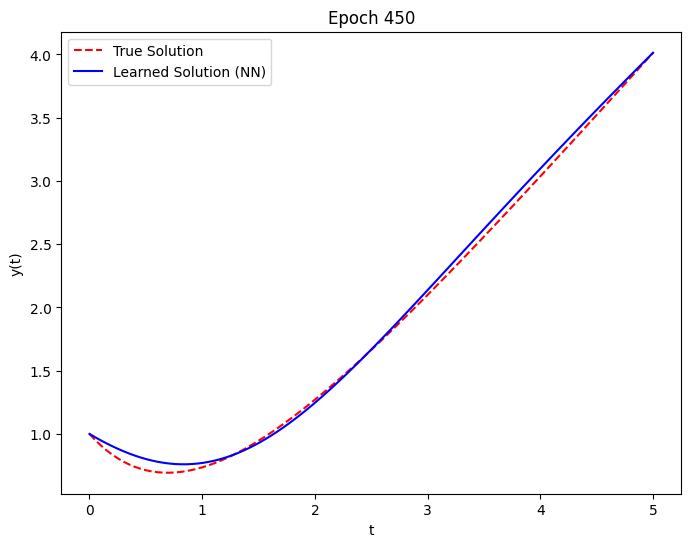

Epoch 460, Test Loss: 0.0018223017686977983


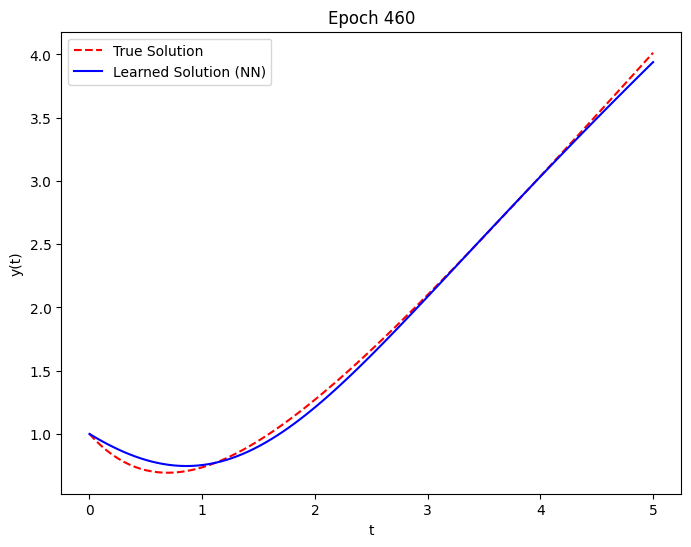

Epoch 470, Test Loss: 0.0023457431234419346


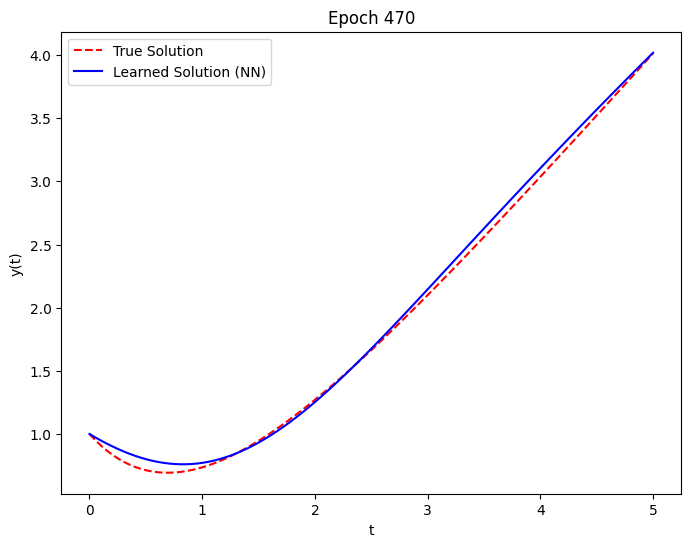

Epoch 480, Test Loss: 0.0016722603468224406


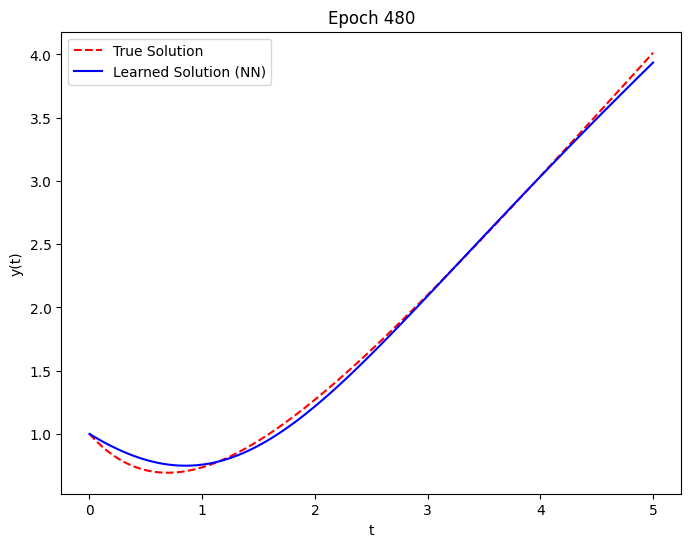

Epoch 490, Test Loss: 0.001558553776703775


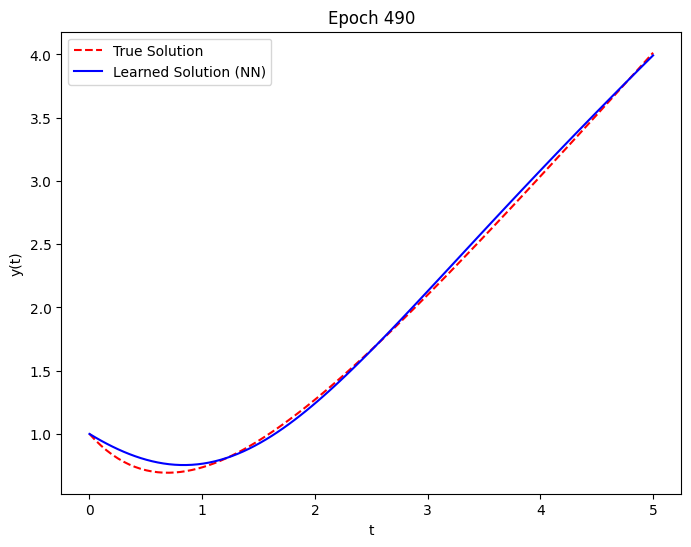

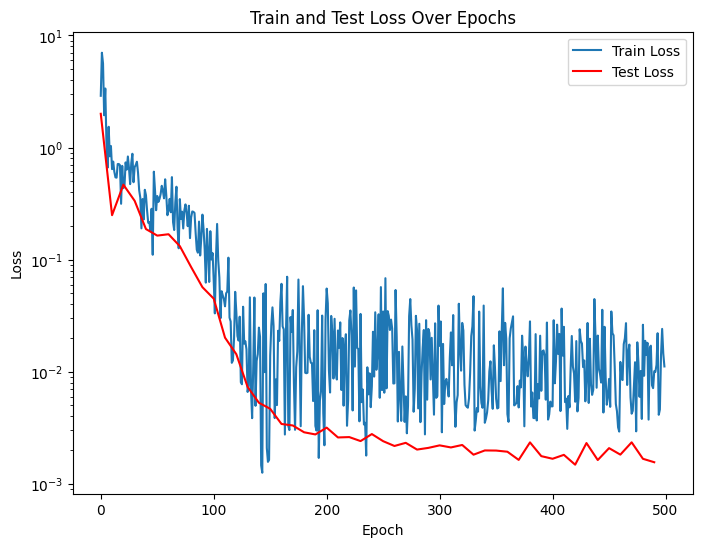

In [ ]:
# Initialize the model
set_seed(1)
T = 5
model = CustomNeuralNet(y0, T)
optimizer = optim.Adam(model.parameters(), lr=0.001)
# Run the training
num_epochs, train_losses, test_losses = train_ode_solver_weight(model, optimizer, T=5, weight_IC=0)
plot_losses(num_epochs, train_losses, test_losses)

Note: to check robustness, we need to redo the experiment over multiple seeds.